# doomscroll
### teaching a small neural network to rank a video feed it has never seen

**the one-line version.** we take real user logs from a short-video app, build a compact neural
network that predicts how much someone will engage with each video, then check how much better the
feed gets when we order videos with that network instead of something dumb like "show the most
popular clip to everyone".

**why it is interesting.** the whole model fits on a laptop cpu (~123k parameters), trains in
minutes, and still beats popularity by a wide, statistically-checked margin. no gpu, no cloud.

**how to read this notebook.** each section starts with a plain-english explanation of *what* we are
doing and *why*, then runs the code and shows the result. you can read the headings alone and still
follow the story.

| part | what you get | is it real data? |
|---|---|---|
| 1–4  | the logs, plots and the learning task | **real** |
| 5–7  | the network, its training curves, its score | **real** |
| 8    | policy-level results (ranking, diversity, retention) | **simulated world** |
| 9    | a live walk-through of one user's feed session | **simulated** |

seed **42** · cpu only · every number regenerates from code in this repo.

## 0 · housekeeping (make it reproducible)
before any results, we pin the environment and print a **fingerprint** of the dataset — a short hash
of each split. if the data ever changes, the hash changes and we know the numbers below are stale.

we also define one tiny helper, `show()`, that renders every table the same clean way.

In [1]:
import json, platform, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display

REPO = Path.cwd()
if not (REPO / "recommender-engine").exists():
    REPO = REPO.parent
ENGINE, EDA = REPO / "recommender-engine", REPO / "eda" / "figures"
RESULTS = REPO / "notes" / "results"
sys.path.insert(0, str(ENGINE))
torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 70)

try:
    commit = subprocess.check_output(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                                     text=True).strip()
except Exception:
    commit = "(local)"

def show(df, caption=None, fmt=None, max_rows=None):
    """Render a compact, index-free, consistently-formatted table."""
    if caption:
        display(Markdown(f"**{caption}**"))
    d = df.head(max_rows) if max_rows else df
    st = d.style.hide(axis="index")
    if fmt:
        st = st.format(fmt)
    display(st.set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left")]},
    ]))

def figure(name, caption=None, width=780):
    display(Markdown(f"**{caption}**") if caption else Markdown(""))
    display(Image(filename=str(EDA / name), width=width))

fp = json.loads((RESULTS / "fingerprint.json").read_text())
print(f"python {platform.python_version()} | torch {torch.__version__} | numpy {np.__version__} "
      f"| cpu-only | seed 42 | git {commit}")
print("data fingerprint (sha256, first 10 chars): "
      + ", ".join(f"{s}={fp['splits'][s]['sha256'][:10]}" for s in ("train", "val", "test")))

python 3.13.14 | torch 2.13.0+cu130 | numpy 2.5.1 | cpu-only | seed 42 | git 92a3a59
data fingerprint (sha256, first 10 chars): train=93f9ca782e, val=2d1345b743, test=897b6a5798


## 1 · the data, in one table
we have three files of impressions (a user was shown a video at a time). they are cut **by time**:
everything in `val` happened *after* `train`, and `test` after `val`. that is the honest way to
check whether the model generalises to the future, not just memorises the past.

each row already carries engineered features (we explain those in section 4) and the engagement
label (section 3).

In [2]:
from feed.data import load_split

sub = ["user_id", "item_id", "day", "ts", "tier", "is_search", "cold_item"]
rows, train_df = [], None
for s in ("train", "val", "test"):
    d = load_split(s, columns=sub)
    if s == "train":
        train_df = d
    rows.append({"split": s, "impressions": f"{len(d):,}", "users": f"{d['user_id'].nunique():,}",
                 "videos": f"{d['item_id'].nunique():,}", "days": f"{d['day'].nunique()}",
                 "search %": f"{d['is_search'].mean():.1%}",
                 "cold-video %": f"{d['cold_item'].mean():.1%}"})
show(pd.DataFrame(rows), "the three splits (time-ordered, no leakage)")
display(Markdown("a peek at the raw training rows:"))
display(train_df.head(5))

**the three splits (time-ordered, no leakage)**

split,impressions,users,videos,days,search %,cold-video %
train,"2,612,256","13,269","568,189",5,11.2%,6.8%
val,"1,959,189","11,218","487,026",4,12.2%,6.2%
test,"1,959,194","10,634","444,869",5,7.5%,5.4%


a peek at the raw training rows:

,user_id,item_id,day,ts,tier,is_search,cold_item
0,1059,2408801,11,1685704949806,0,1,0
1,1059,650060,11,1685704949806,0,1,0
2,1059,3078261,11,1685704949806,0,1,0
3,1059,2776220,11,1685704949806,2,1,0
4,1059,1262505,11,1685715750958,0,1,0


## 2 · exploratory data analysis
before modelling anything, we looked hard at the data. every plot below lives in `eda/figures/`
(some production-ready figures were also regenerated during the study into the same folder).

we grouped them by the question they answer:

1. **how much and when** — cleaning, volume over time, sessions, temporal rhythms
2. **what engages** — tiers, per-action rates, watch behaviour, action co-occurrence
3. **who and what** — user activity, item popularity, category mix, cold-start drift
4. **are the features usable** — feature viability, deciles, correlations, interest concentration

### how much and when

**what survived cleaning — rows kept/dropped at each step**

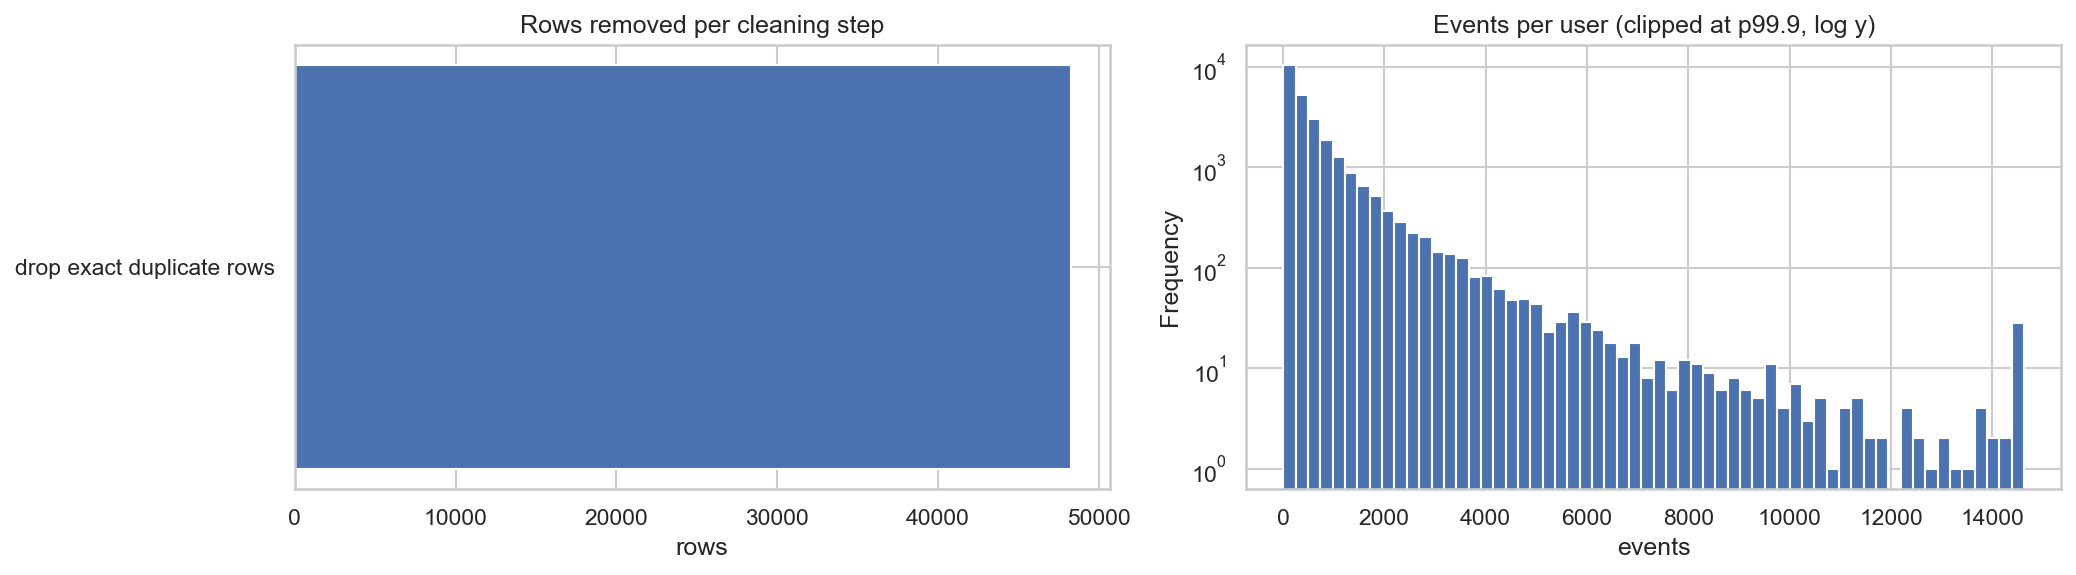

**raw log volume and engagement prevalence**

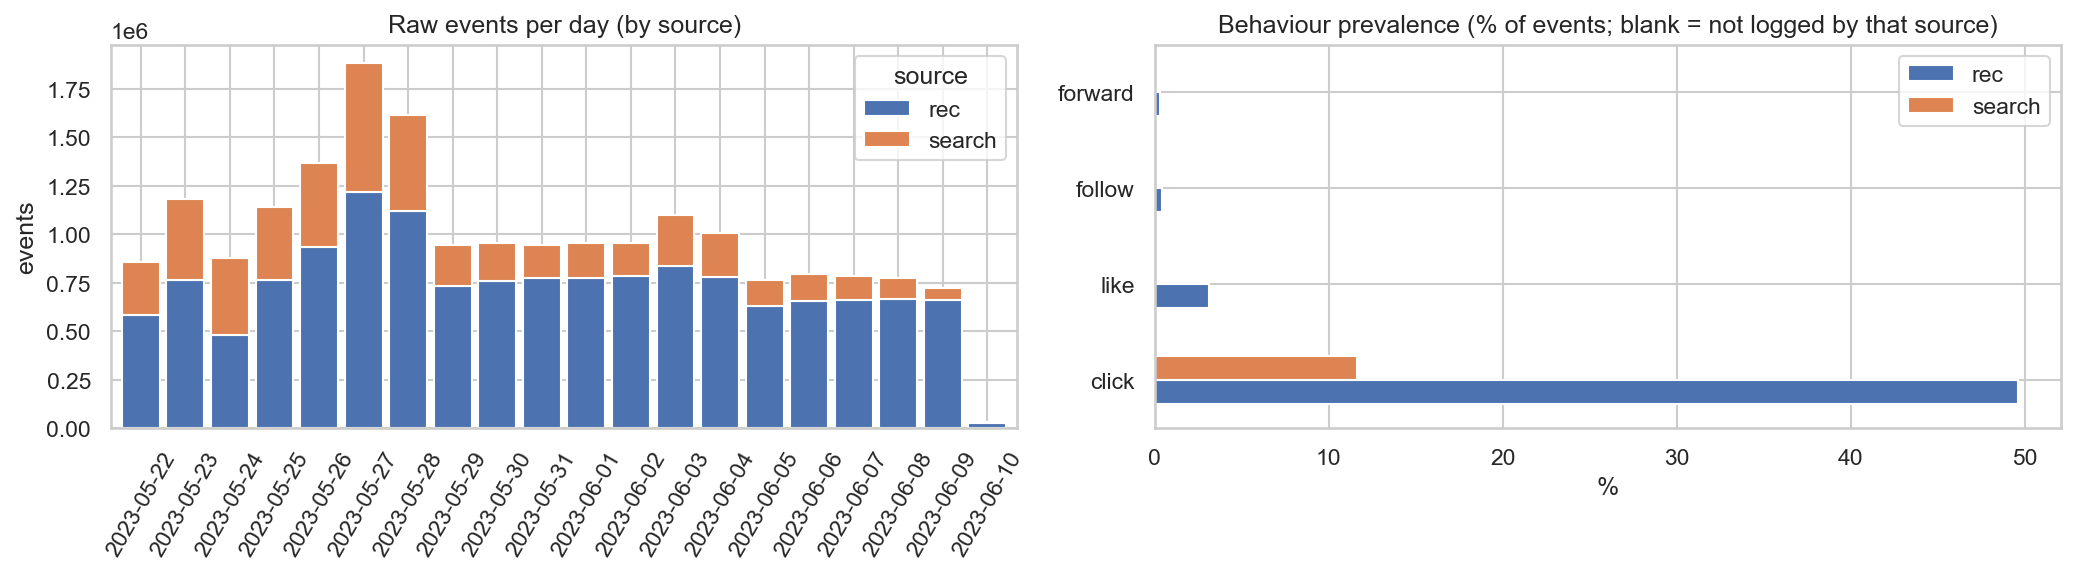

**activity by hour / weekday — when people scroll**

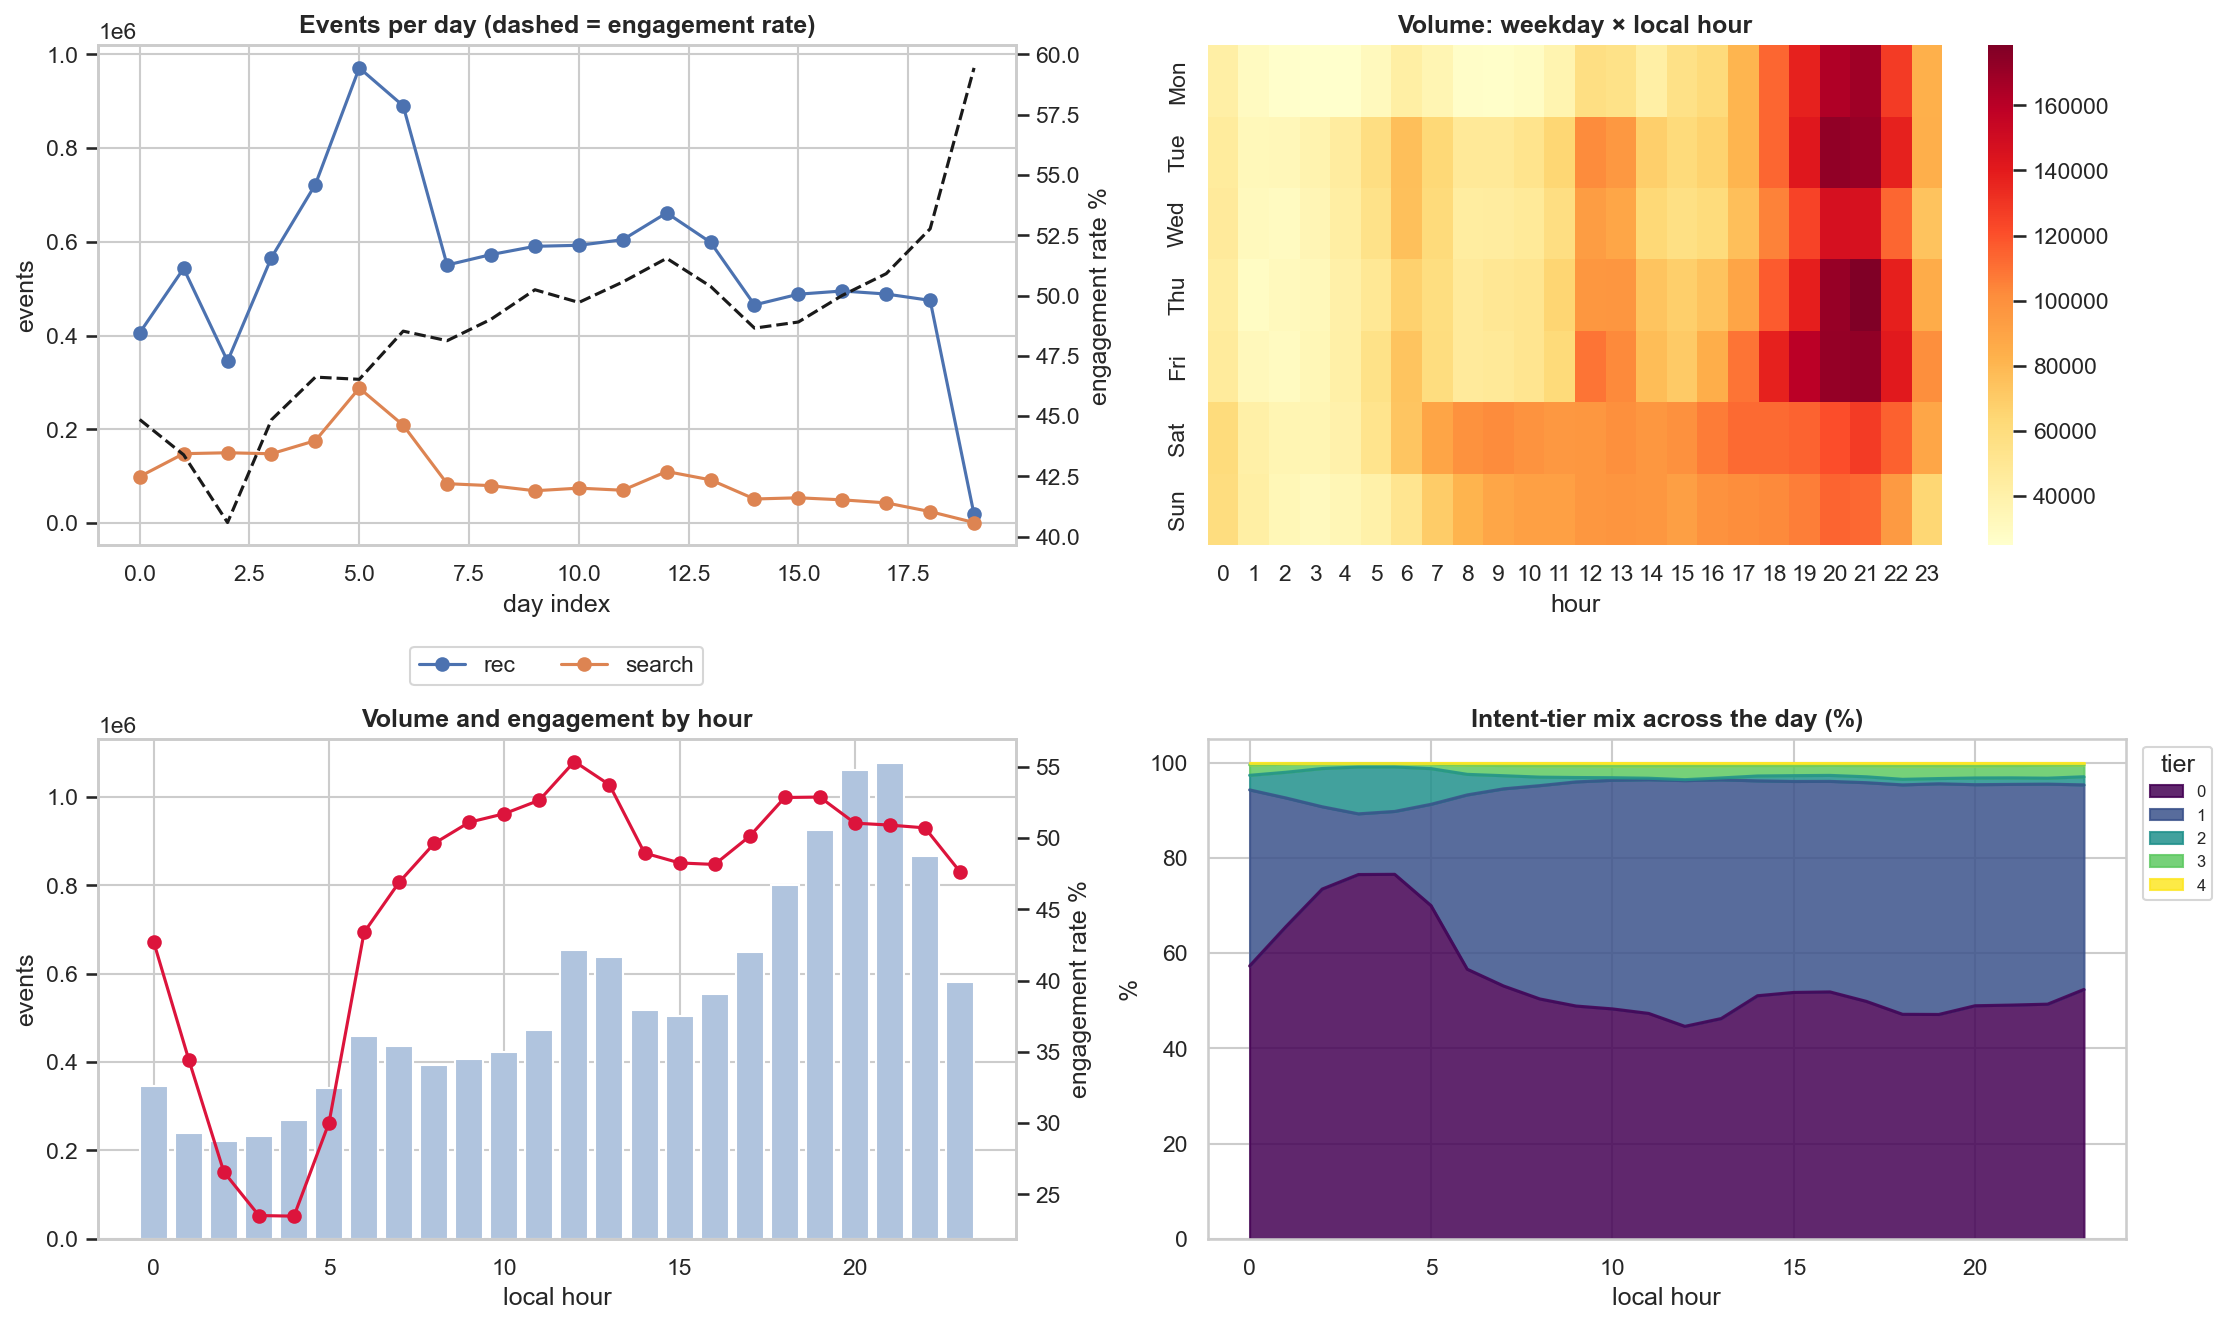

**how long a sitting tends to last**

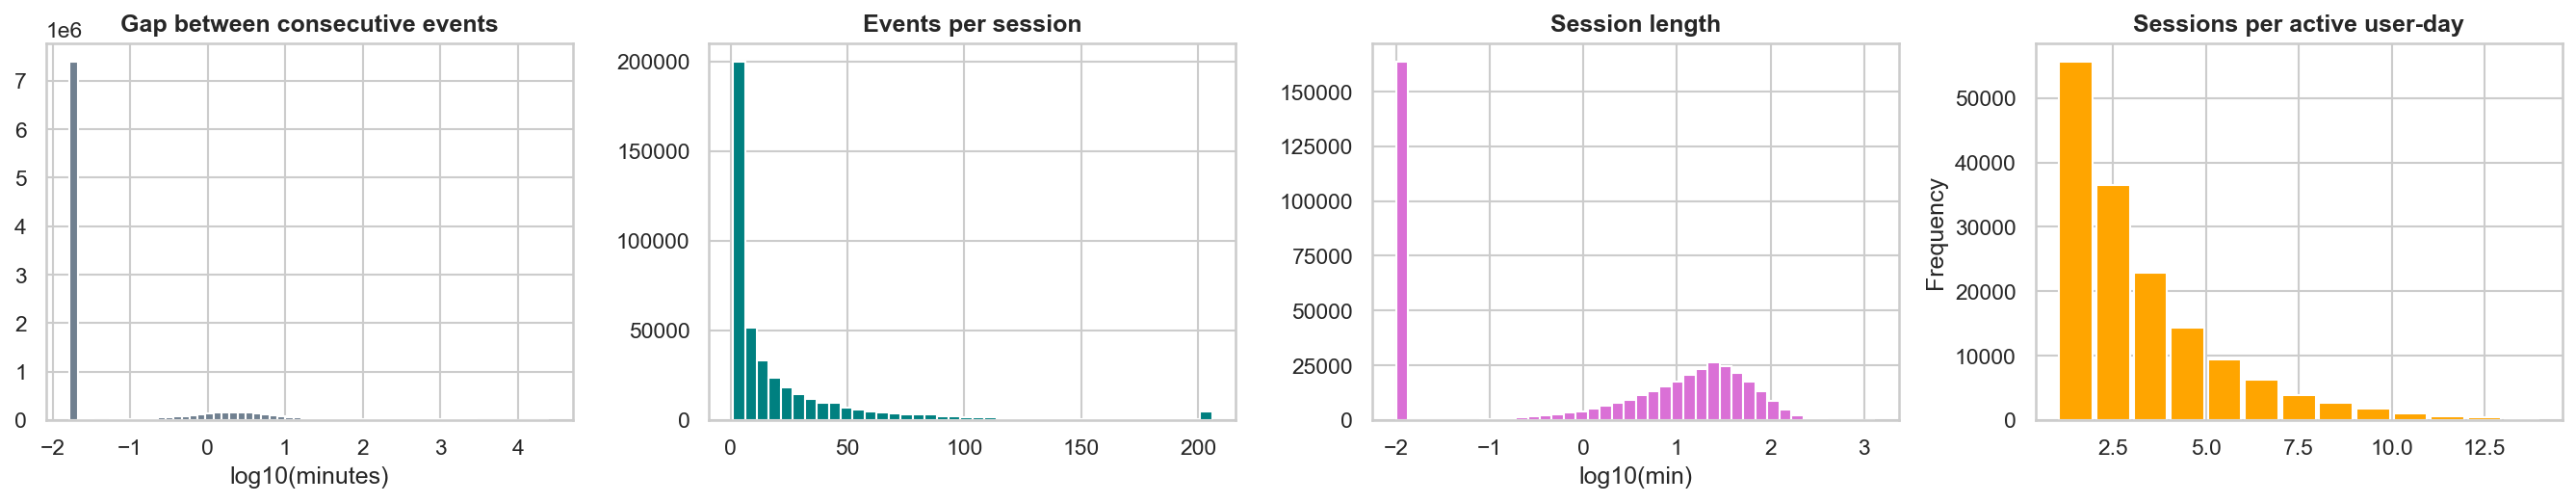

### what engages

**our graded engagement label (tier) — most impressions are low tier**

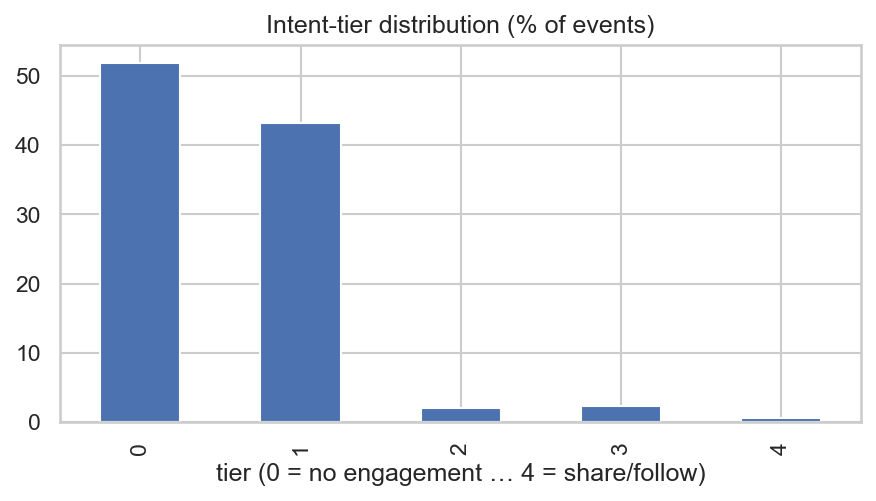

**how rare each action is: clicks common, follows rare**

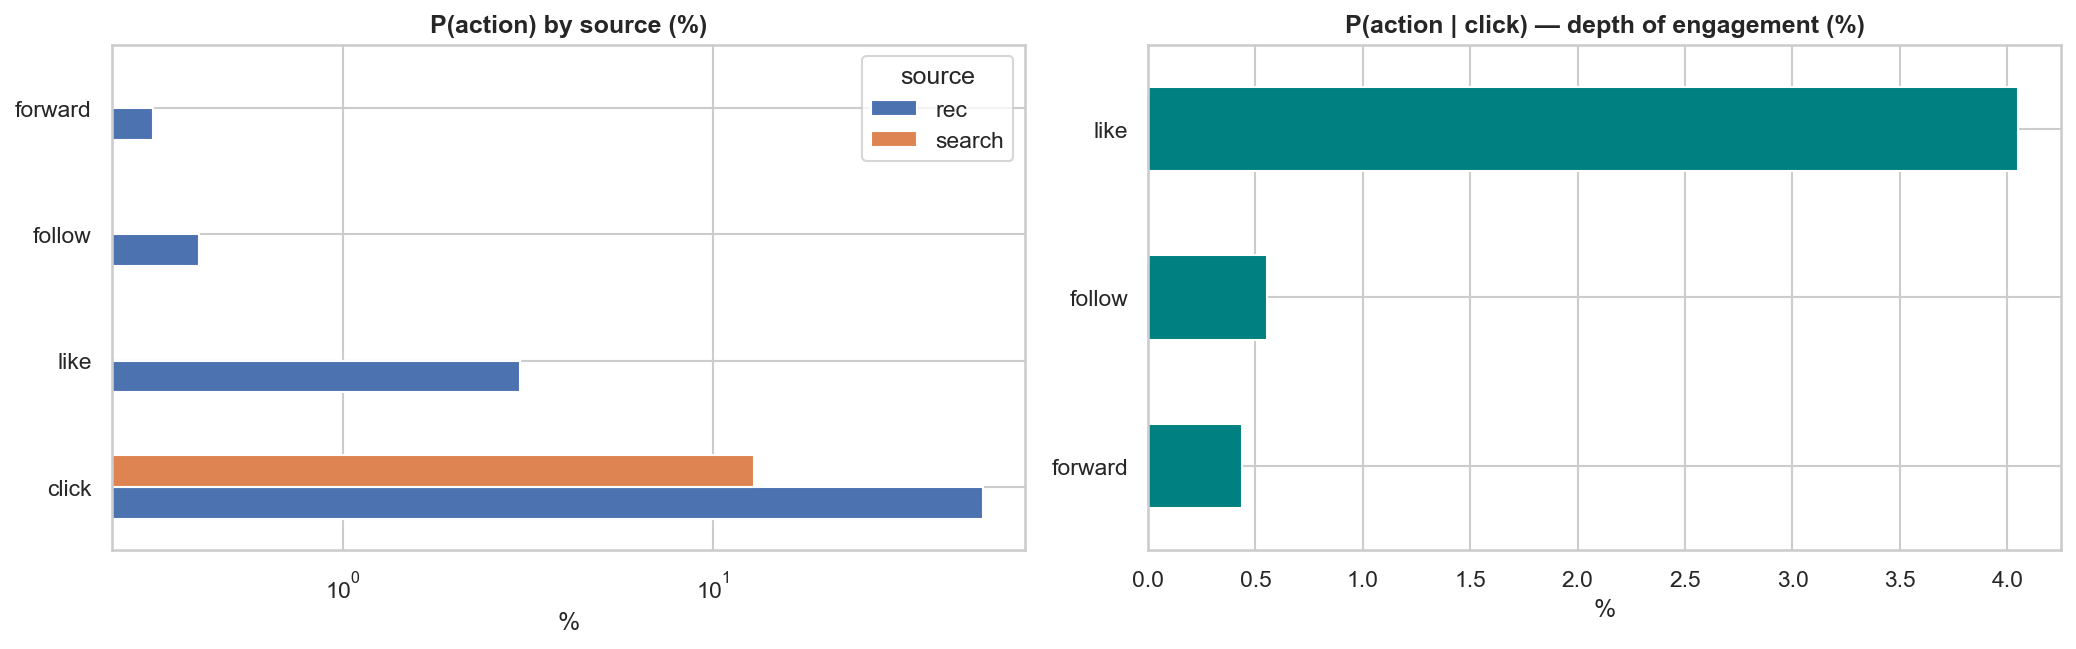

**the watch-fraction distribution — a proxy for satisfaction**

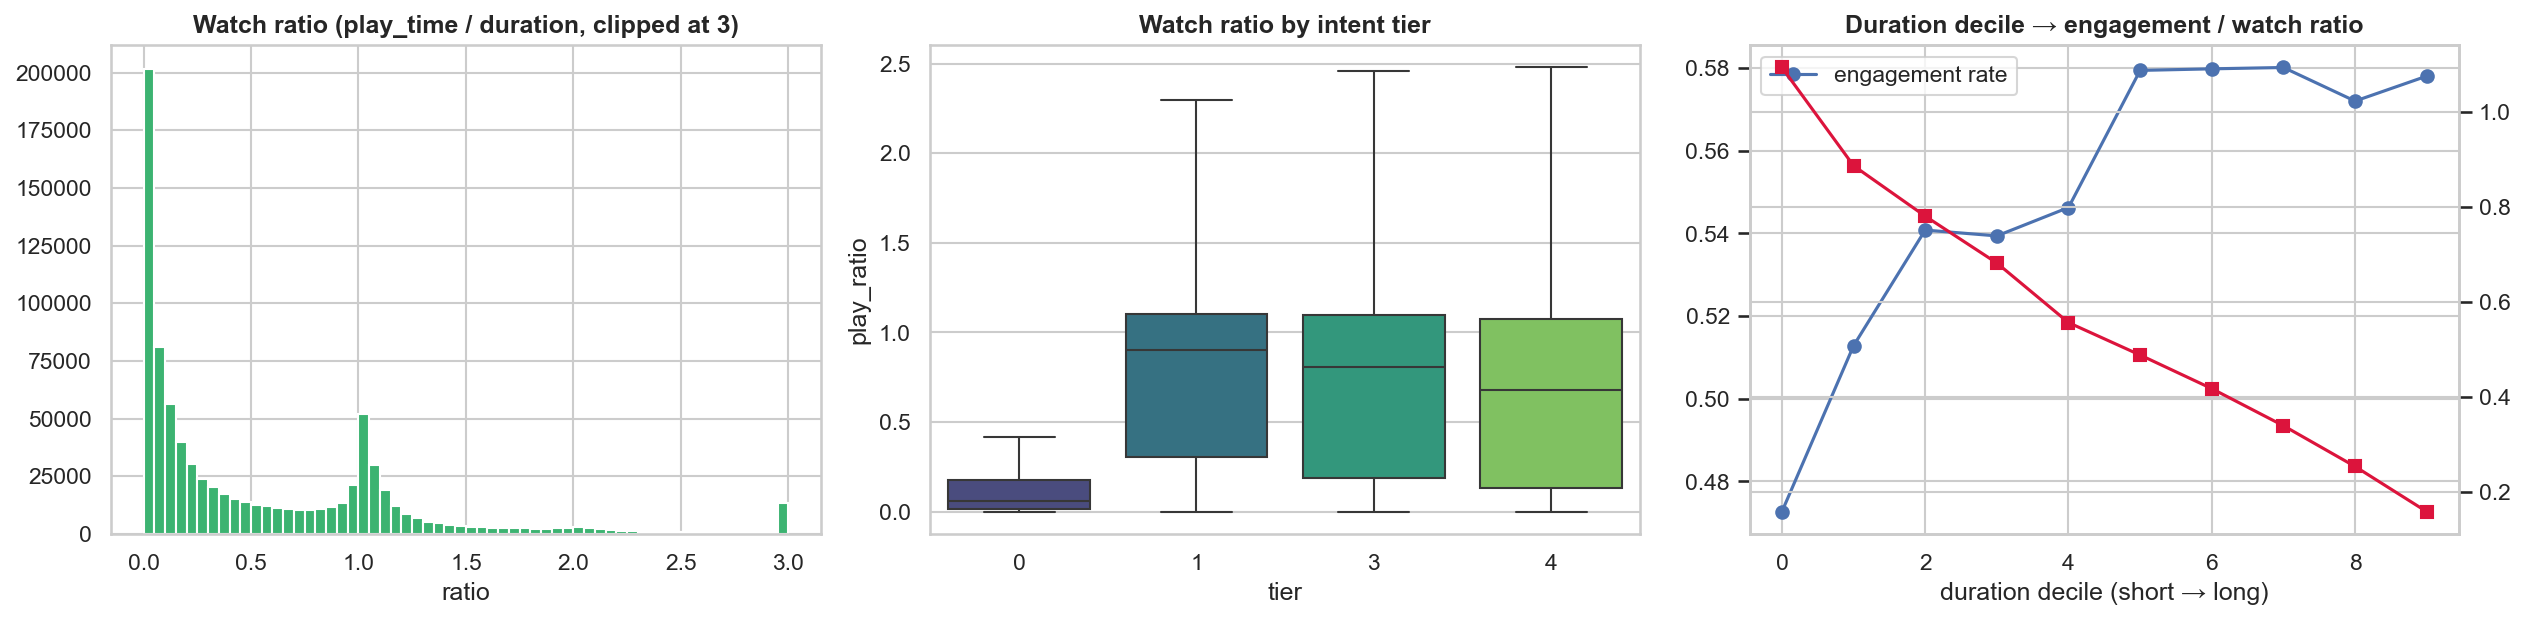

**which actions happen together**

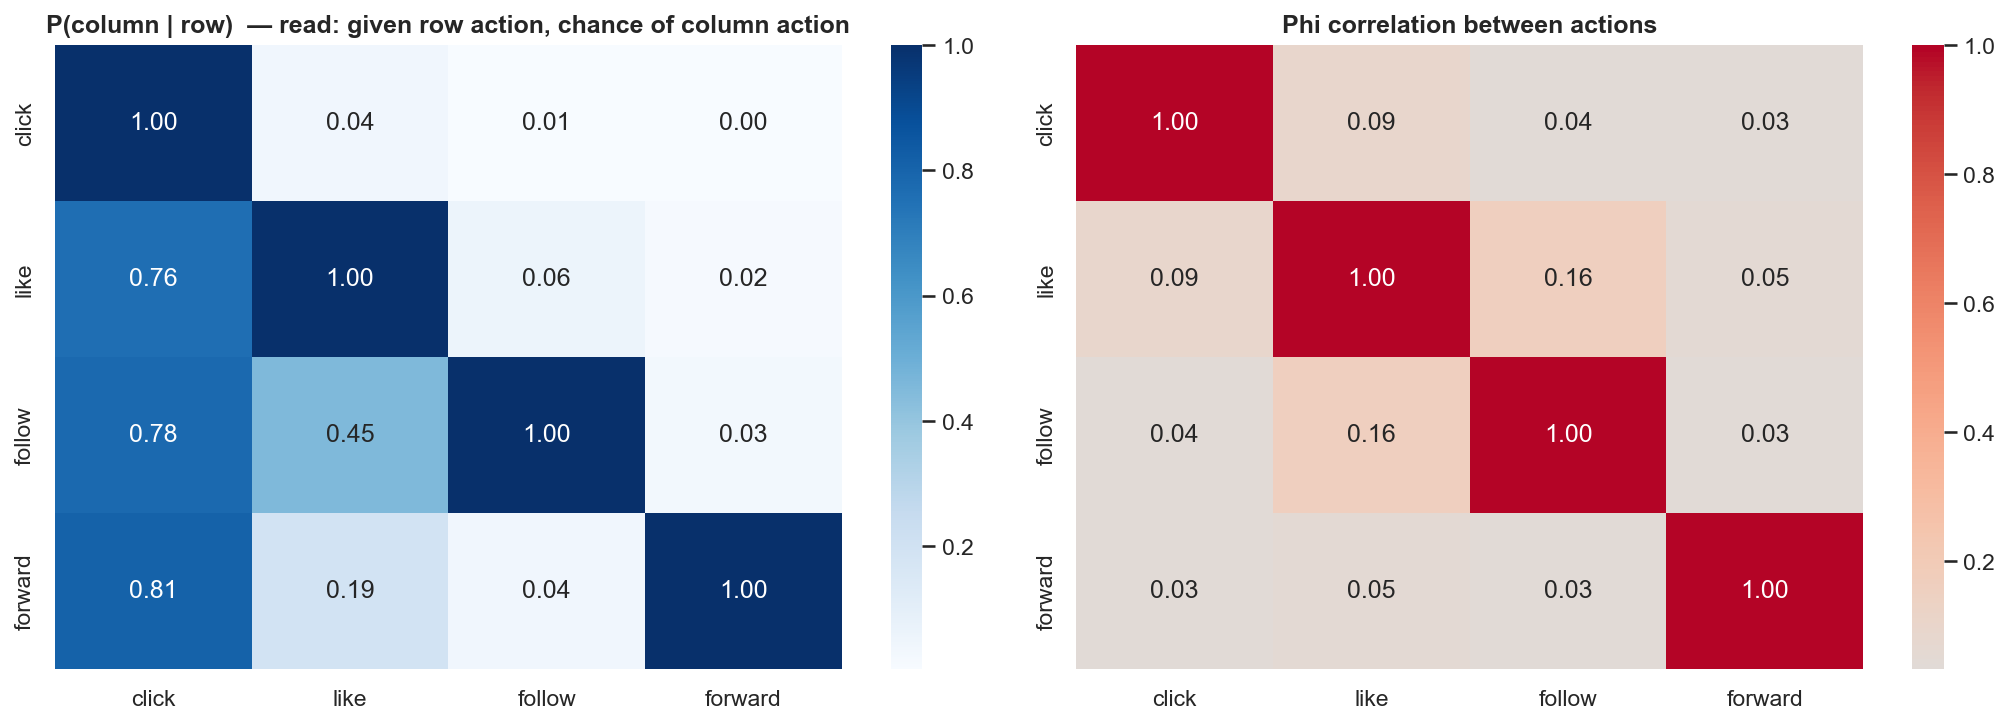

**engagement level by search vs feed**

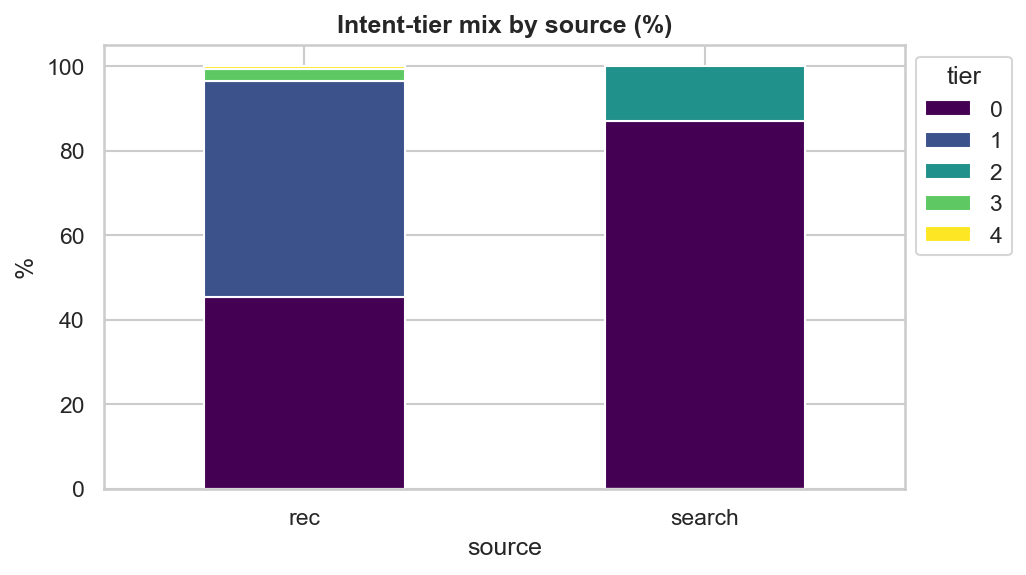

### who and what

**impressions per user — heavy users dominate, a long tail**

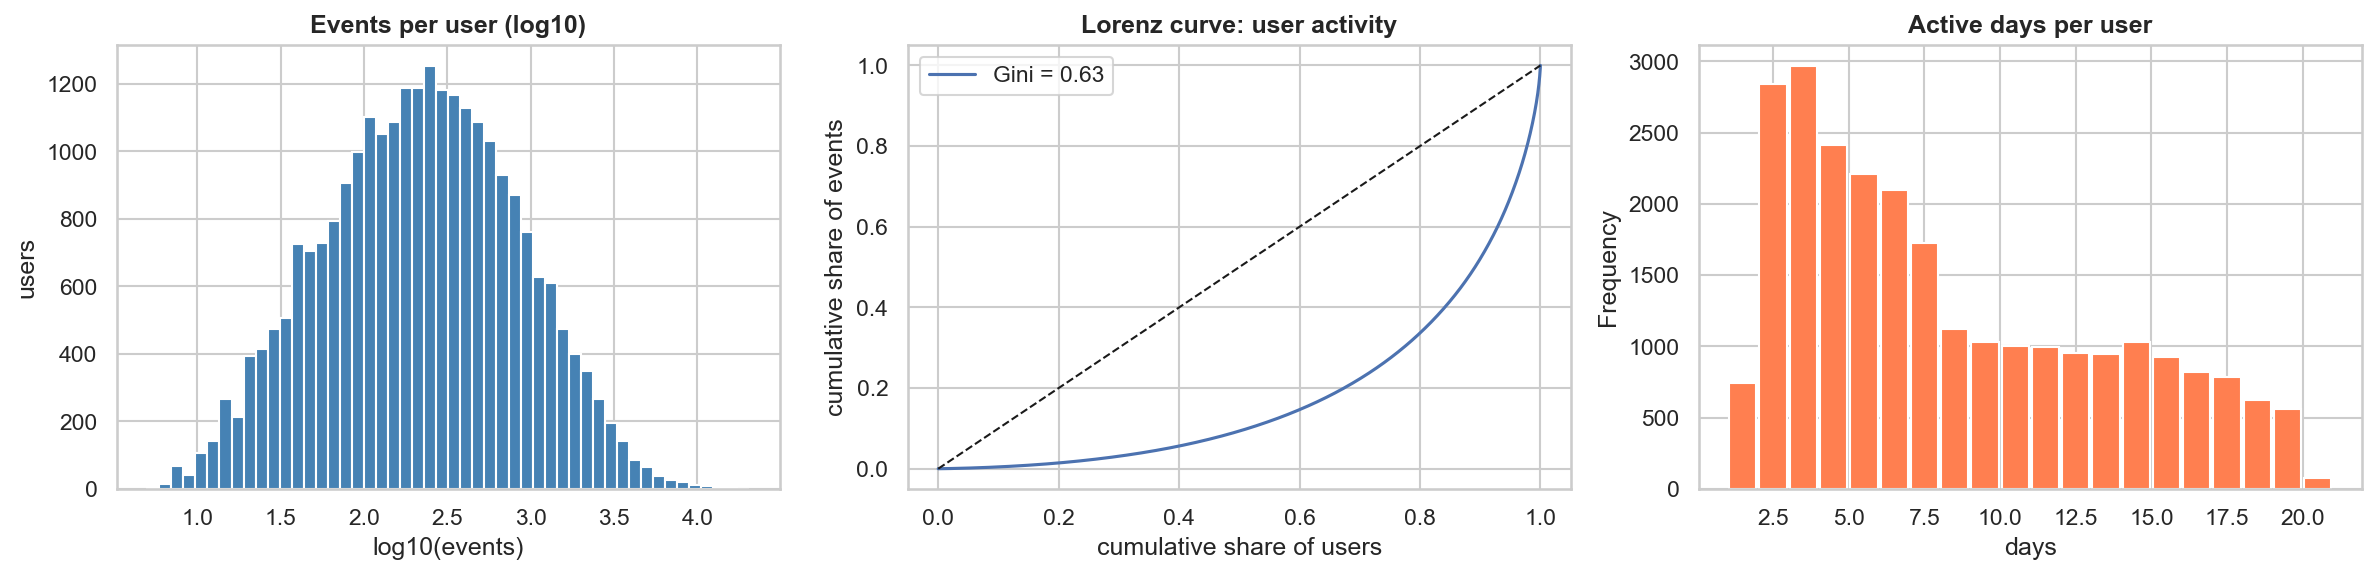

**impressions per video — a classic popularity long tail**

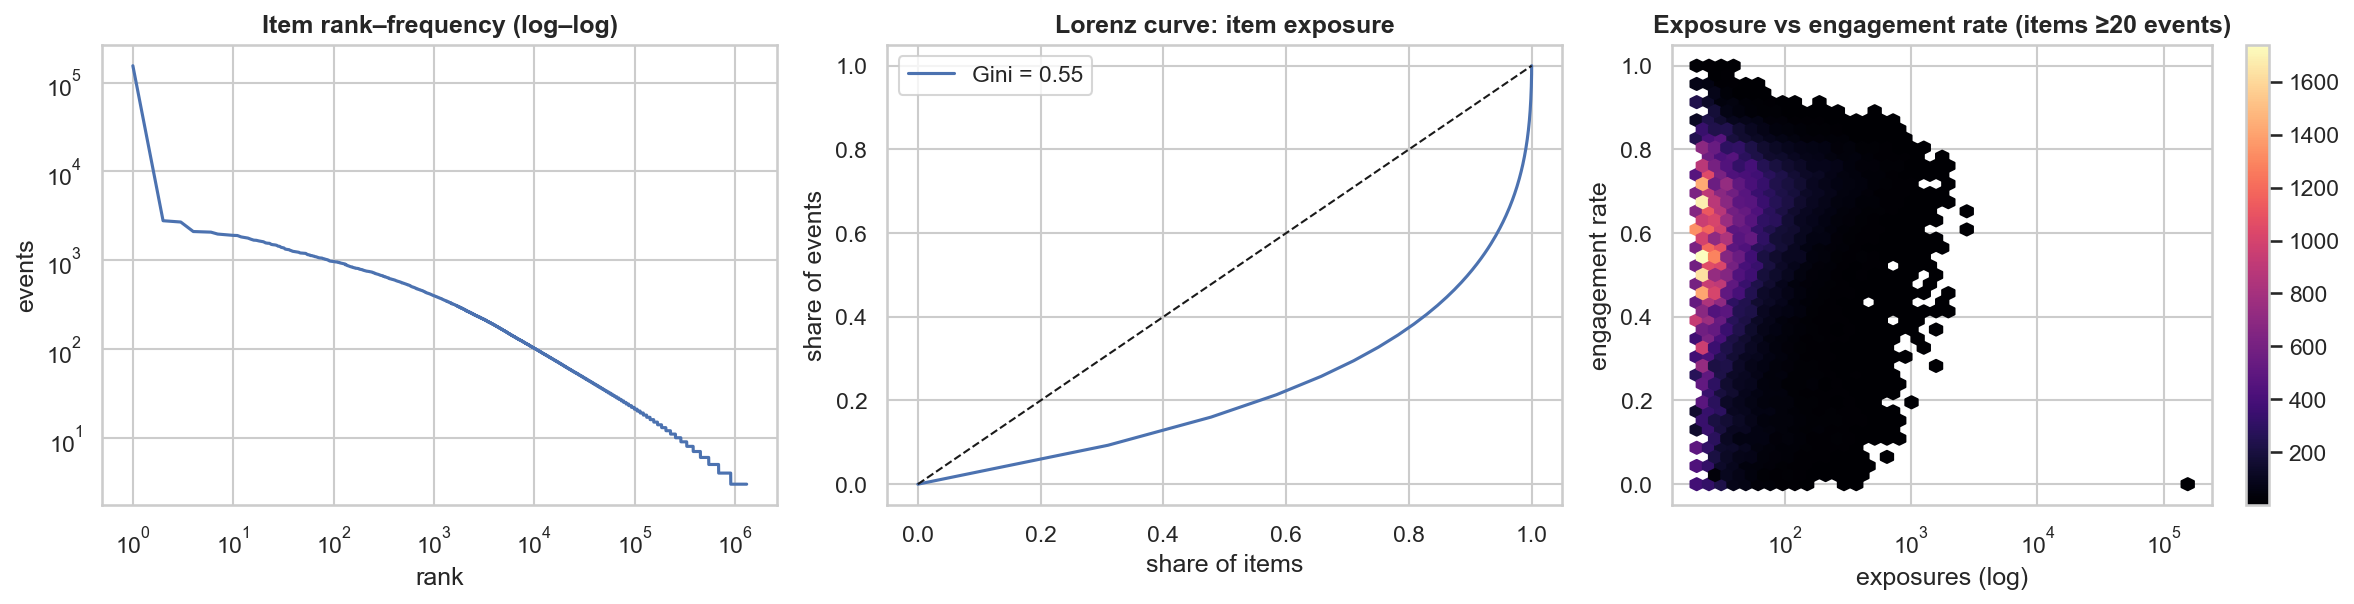

**topic mix across the catalogue**

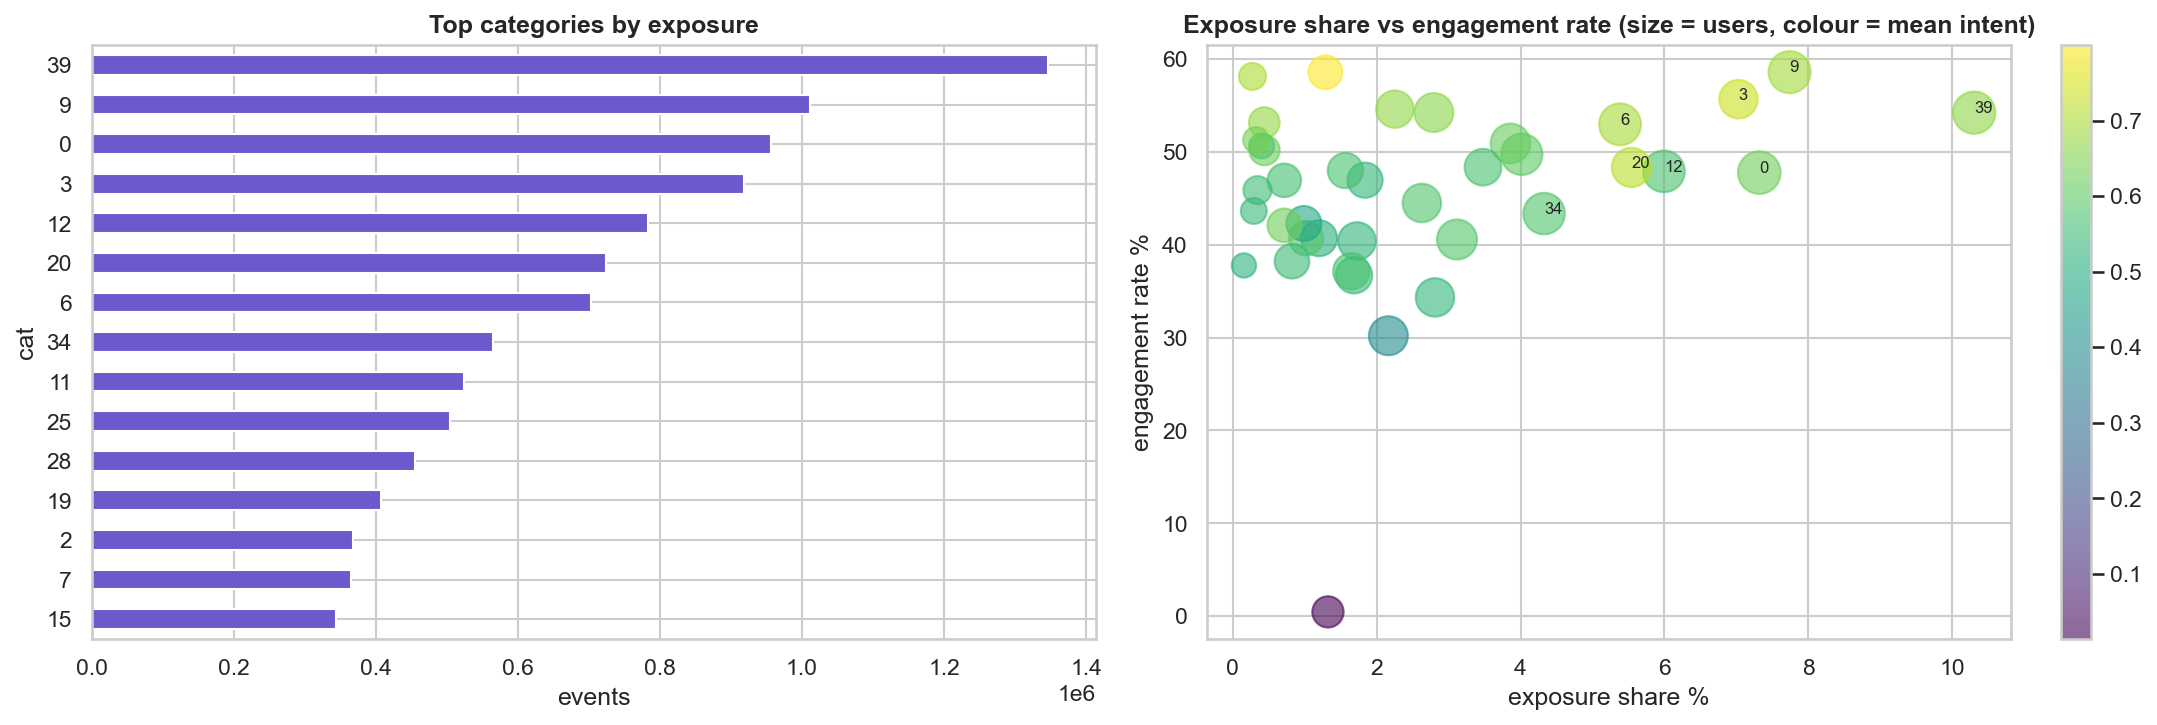

**which topics trigger which actions**

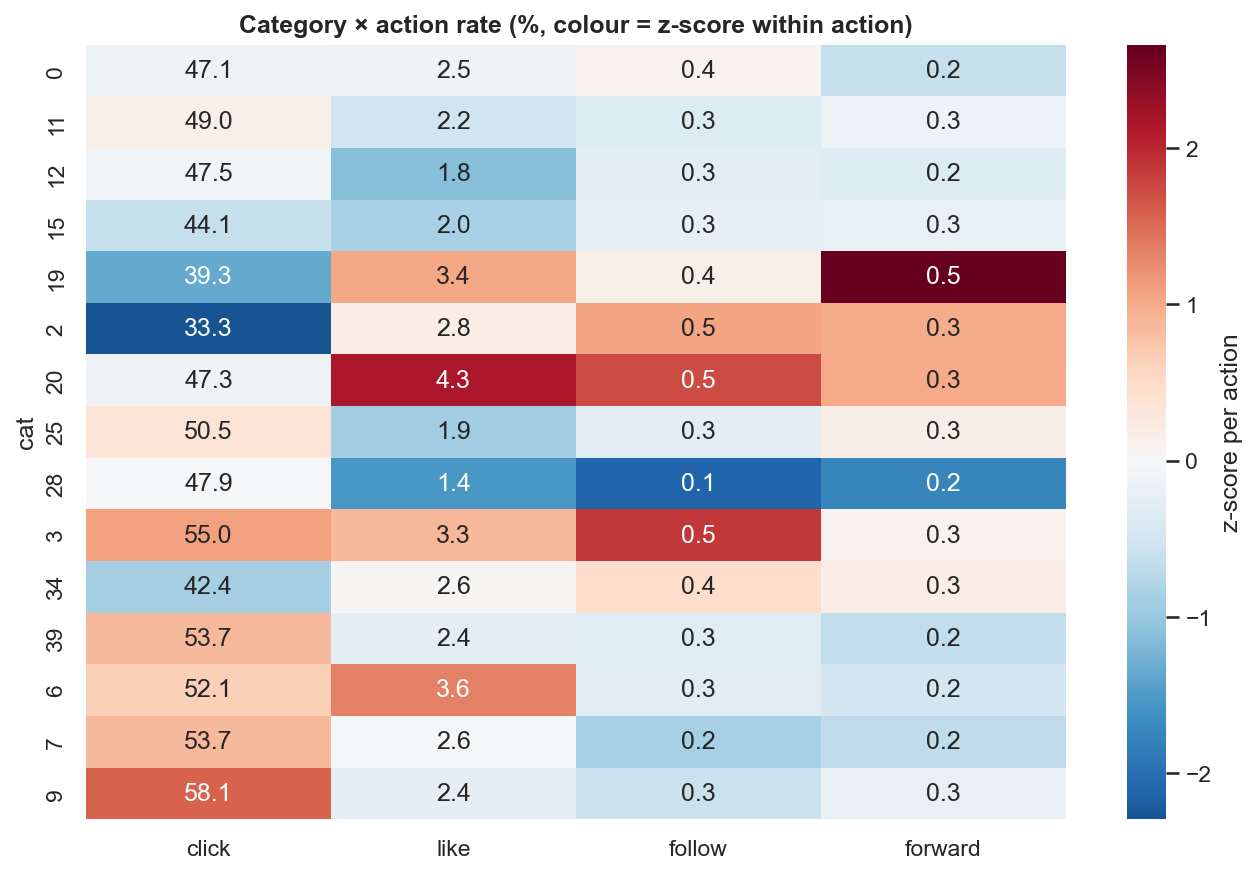

**repeat vs fresh content and recency effects**

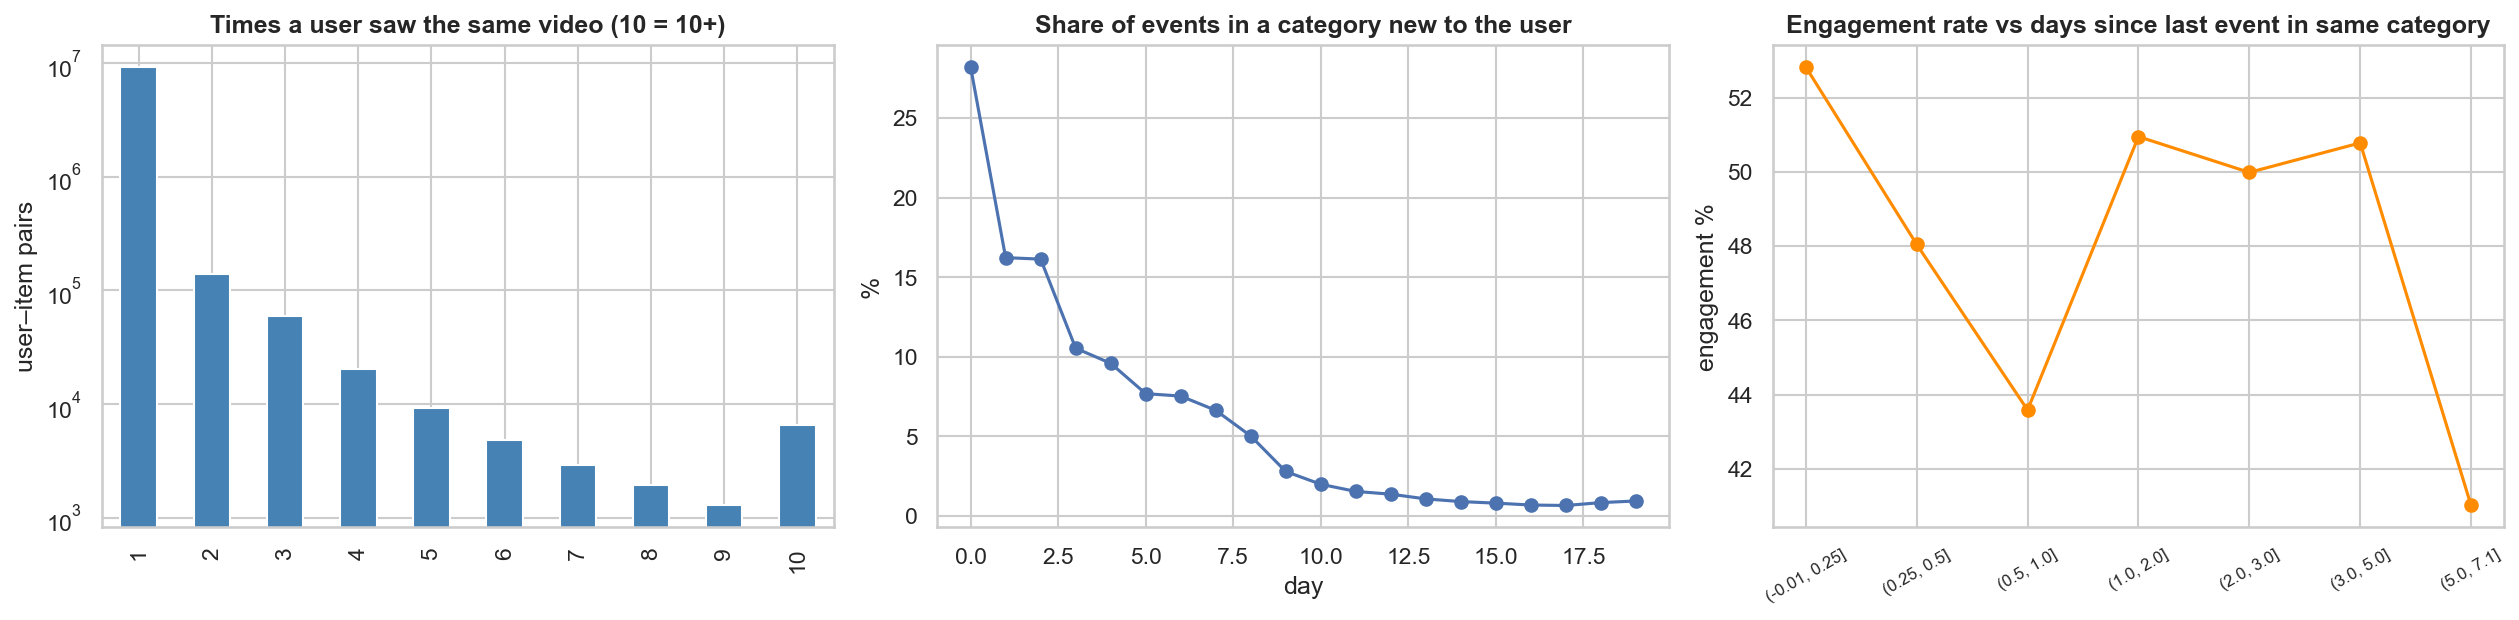

**how cold items and user interests drift over time**

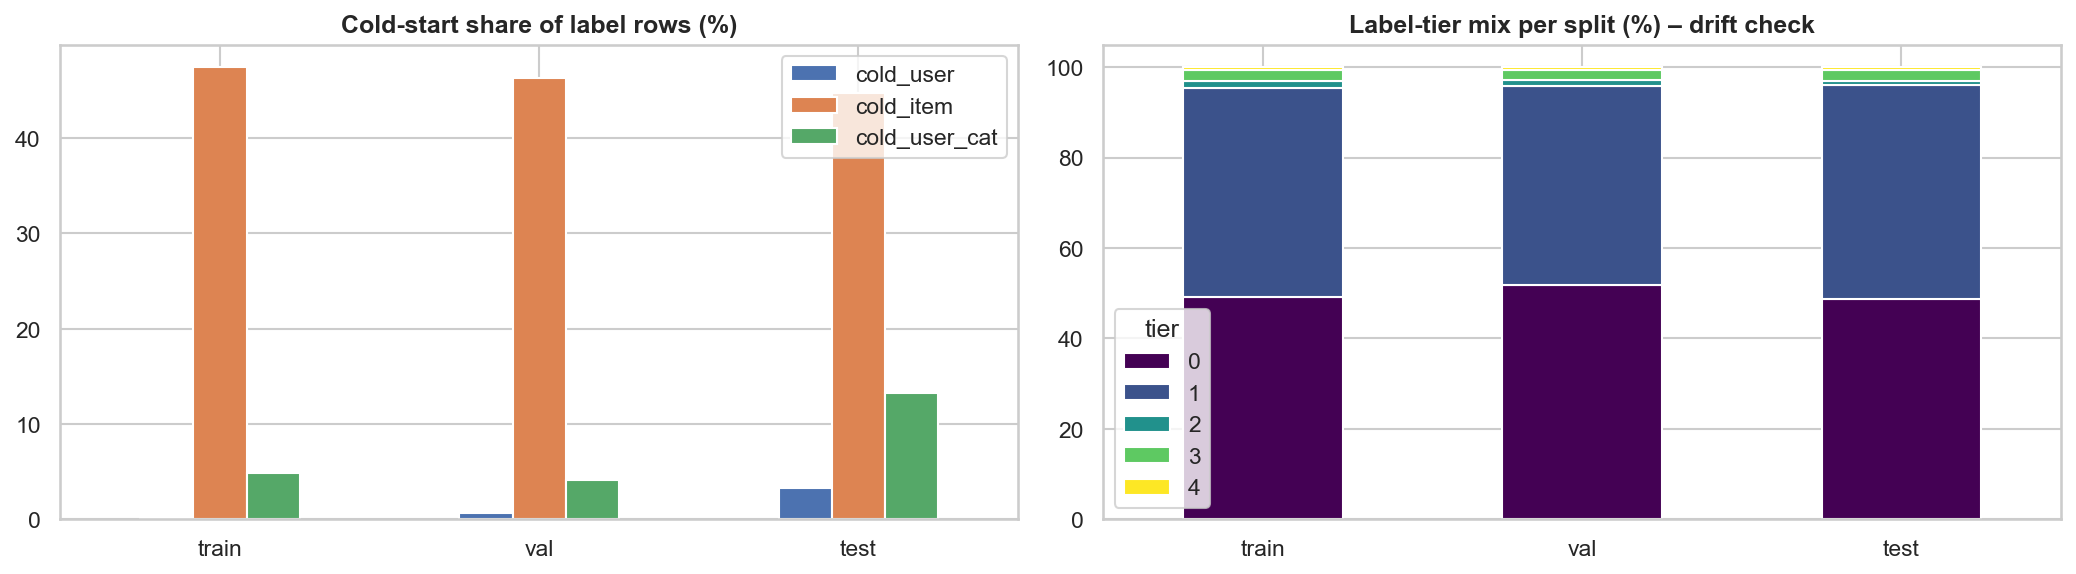

**user cohorts by activity — who the heavy scrollers are**

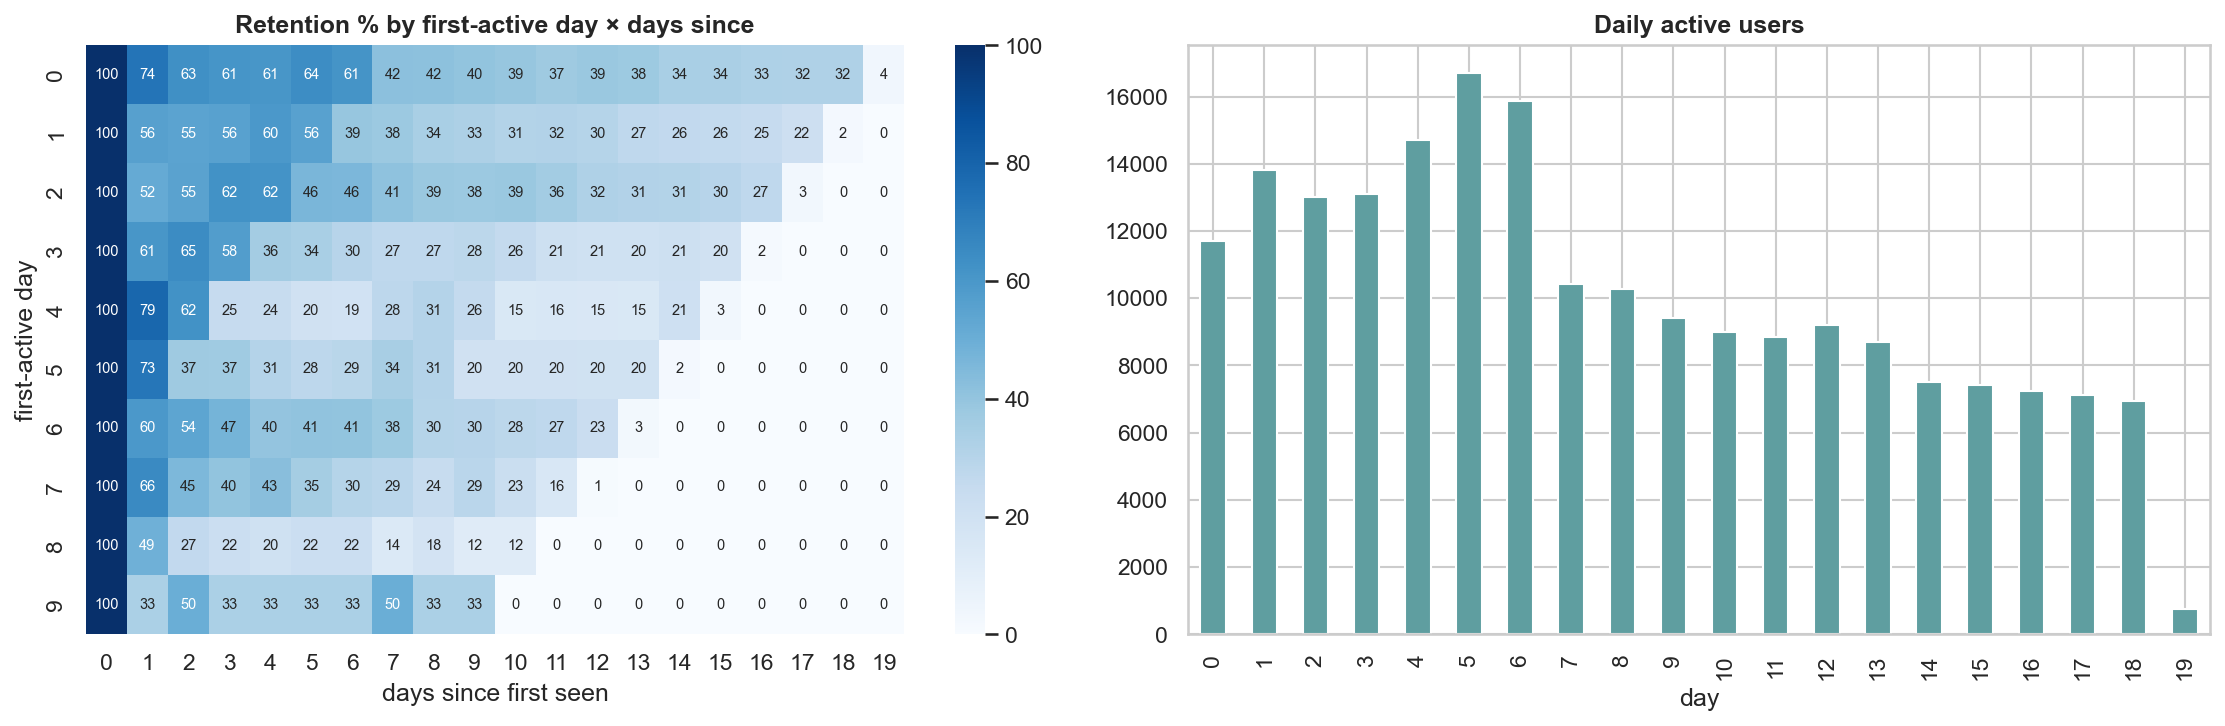

### are the features usable

**feature correlation — no two features are redundant**

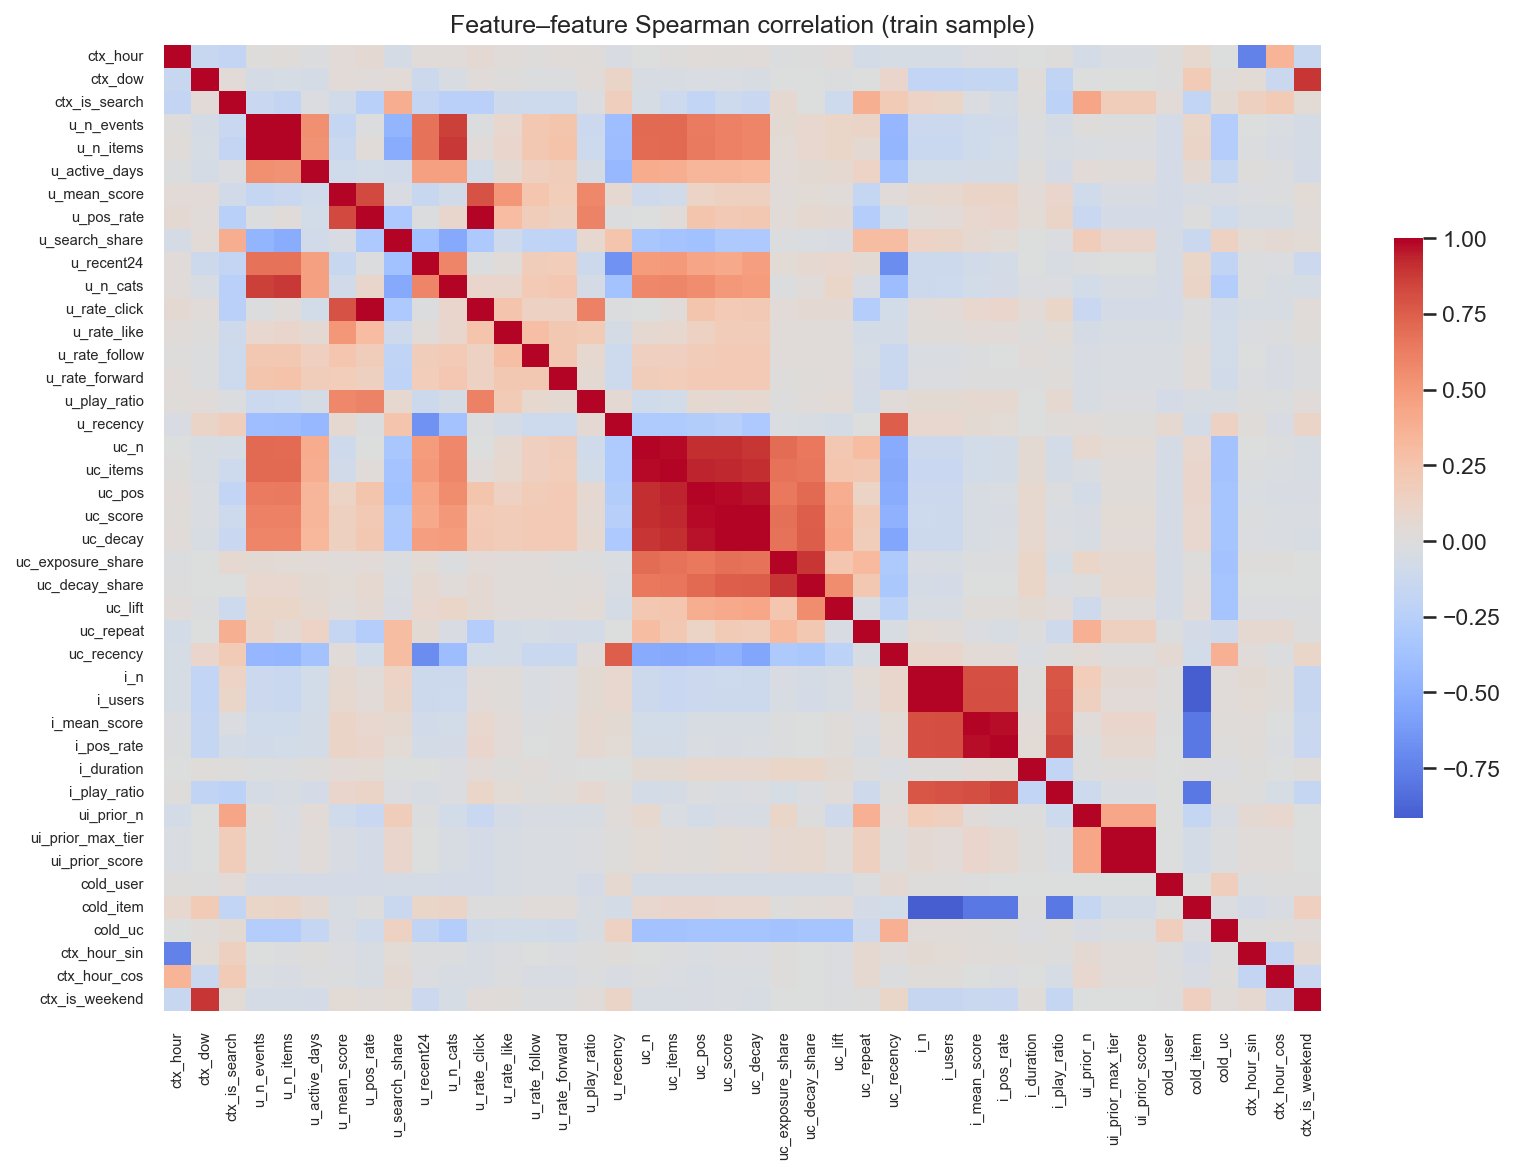

**how much signal each feature carries**

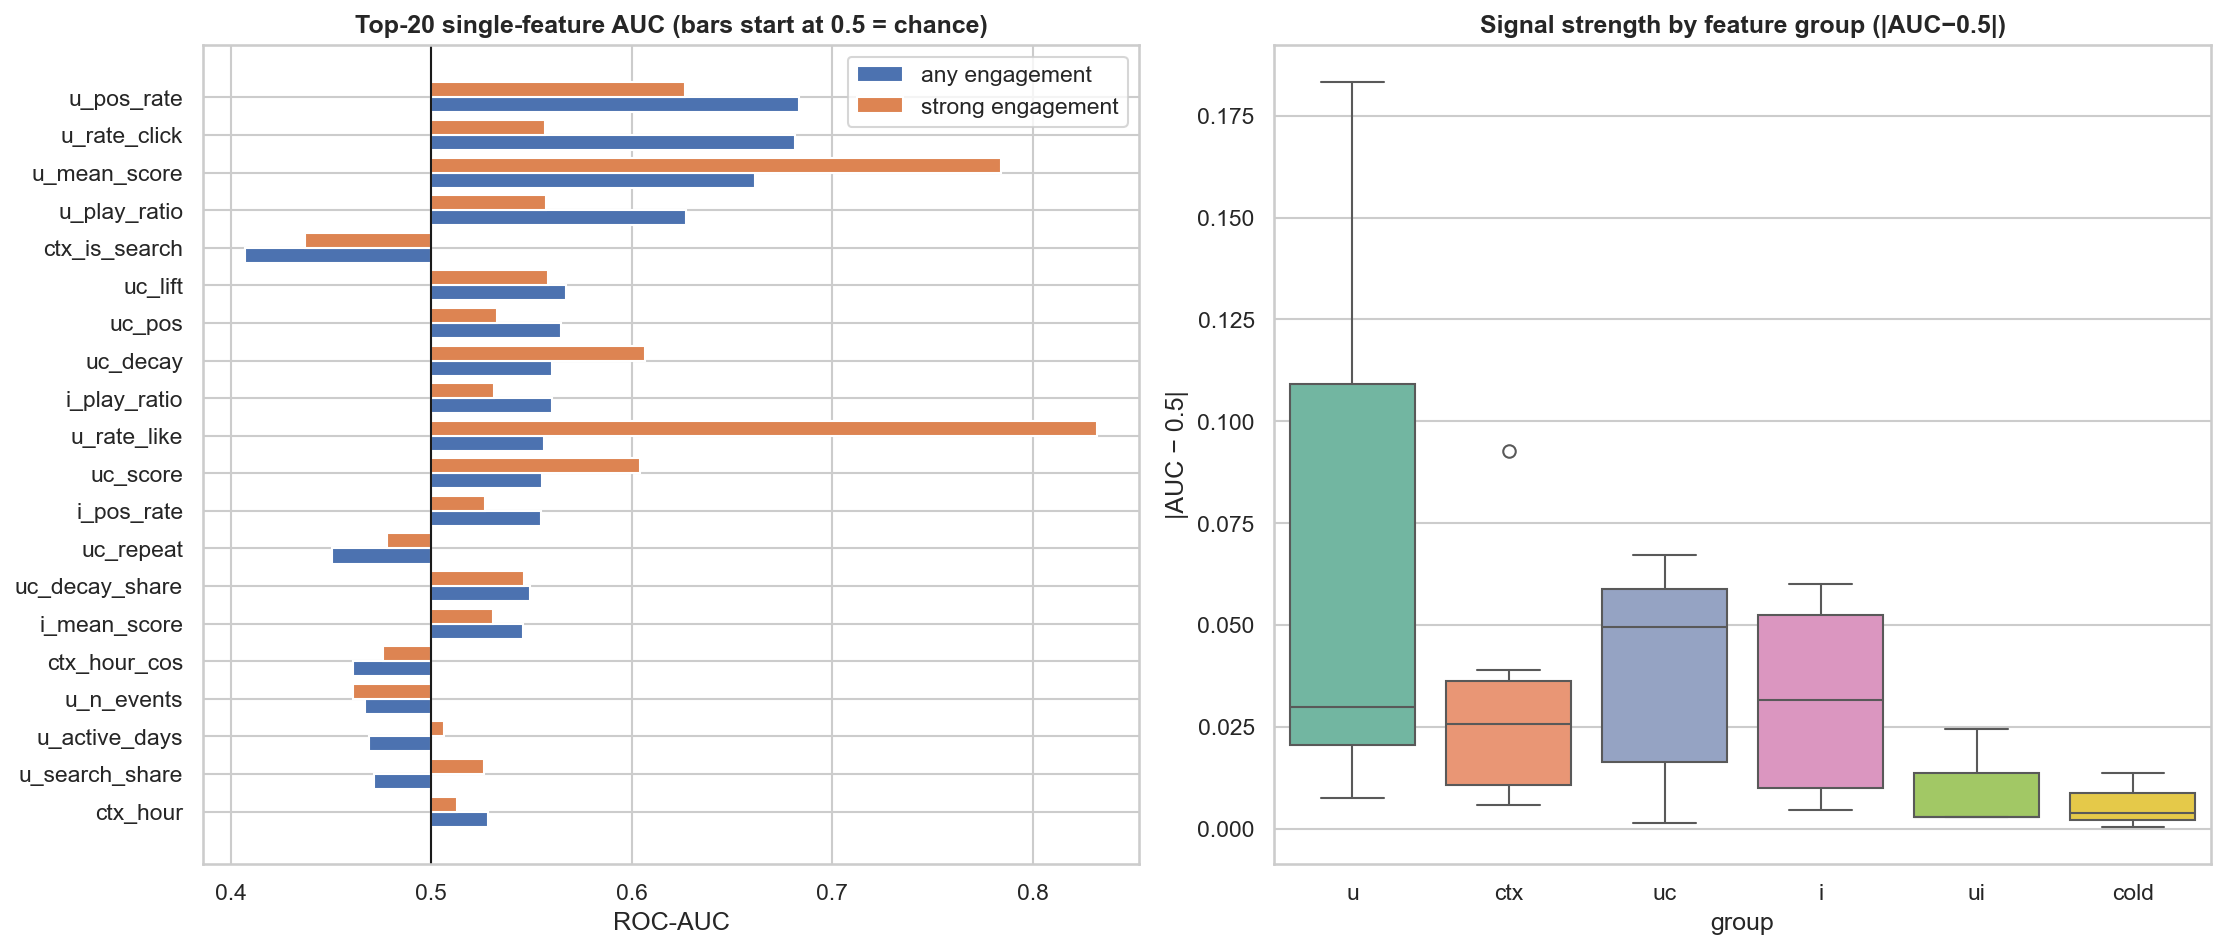

**features split into deciles — monotone where it should be**

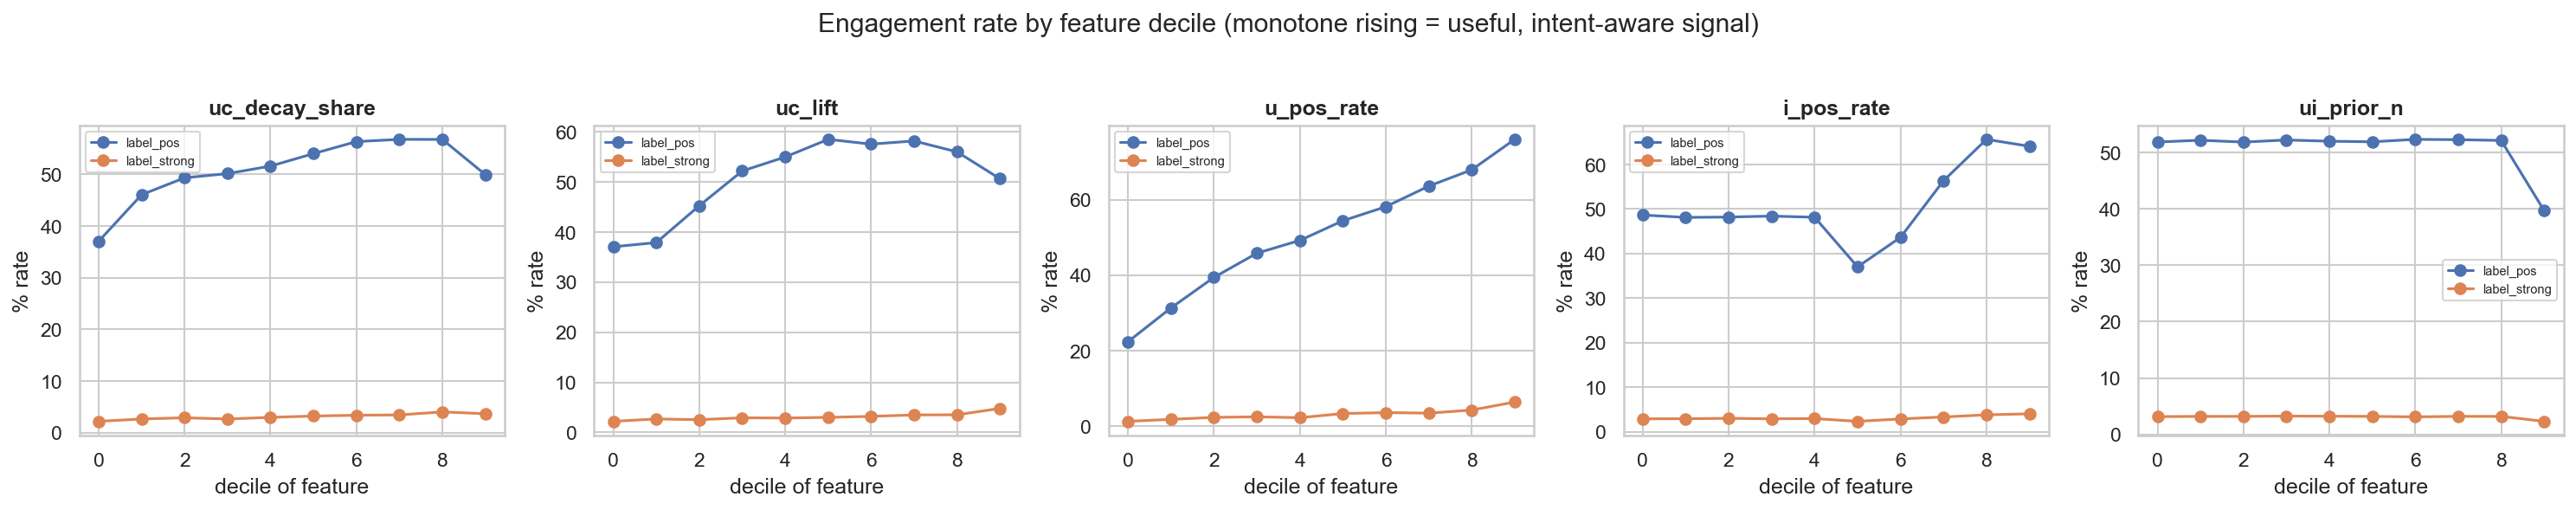

**how concentrated each user's interests are**

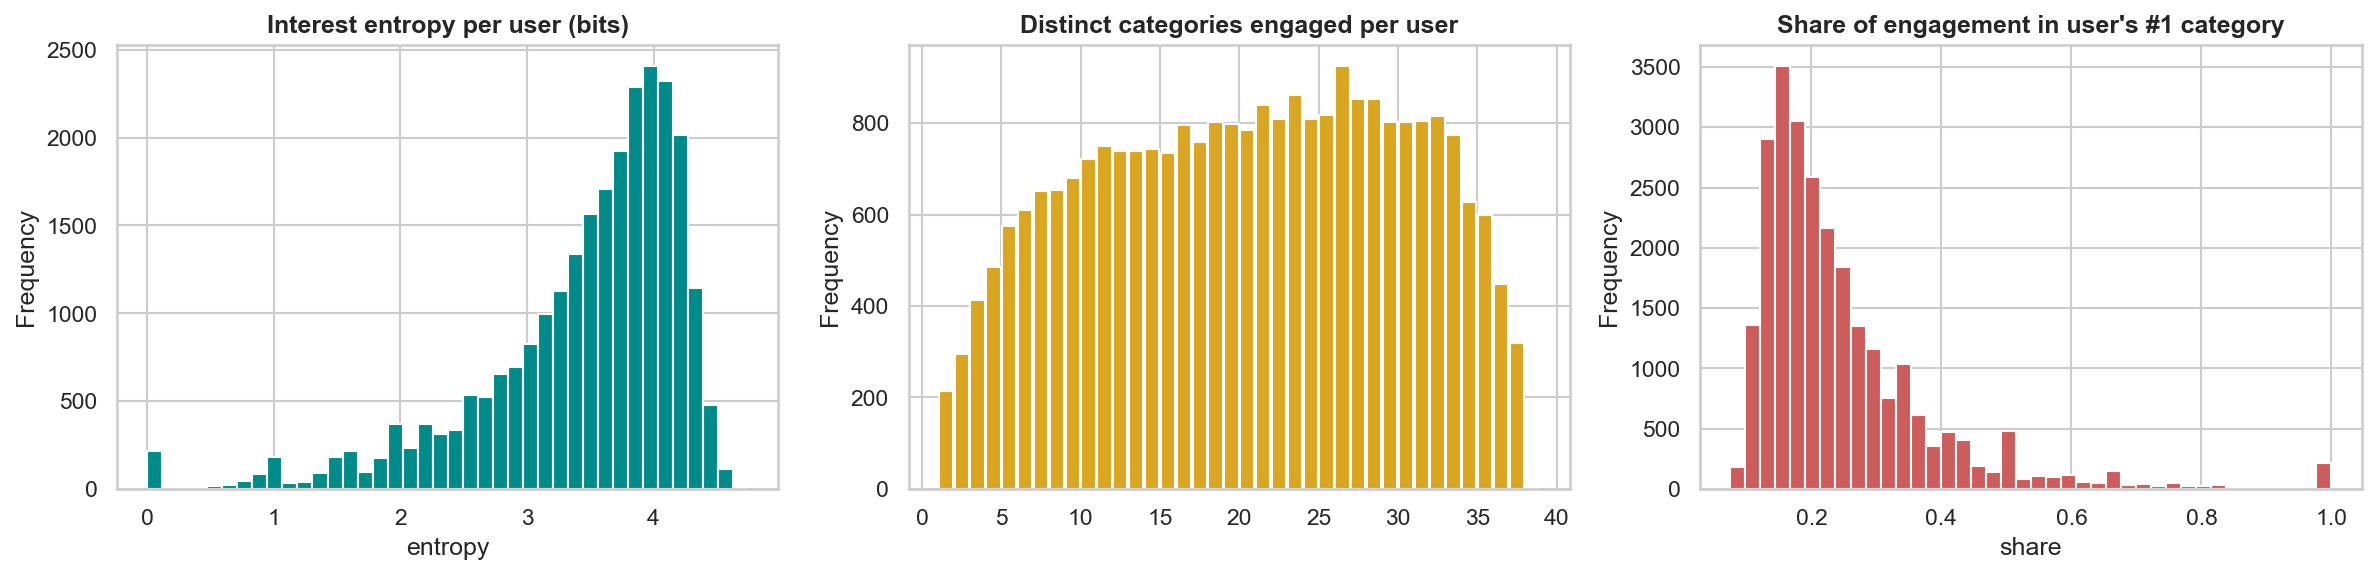

**users vs their interest profile**

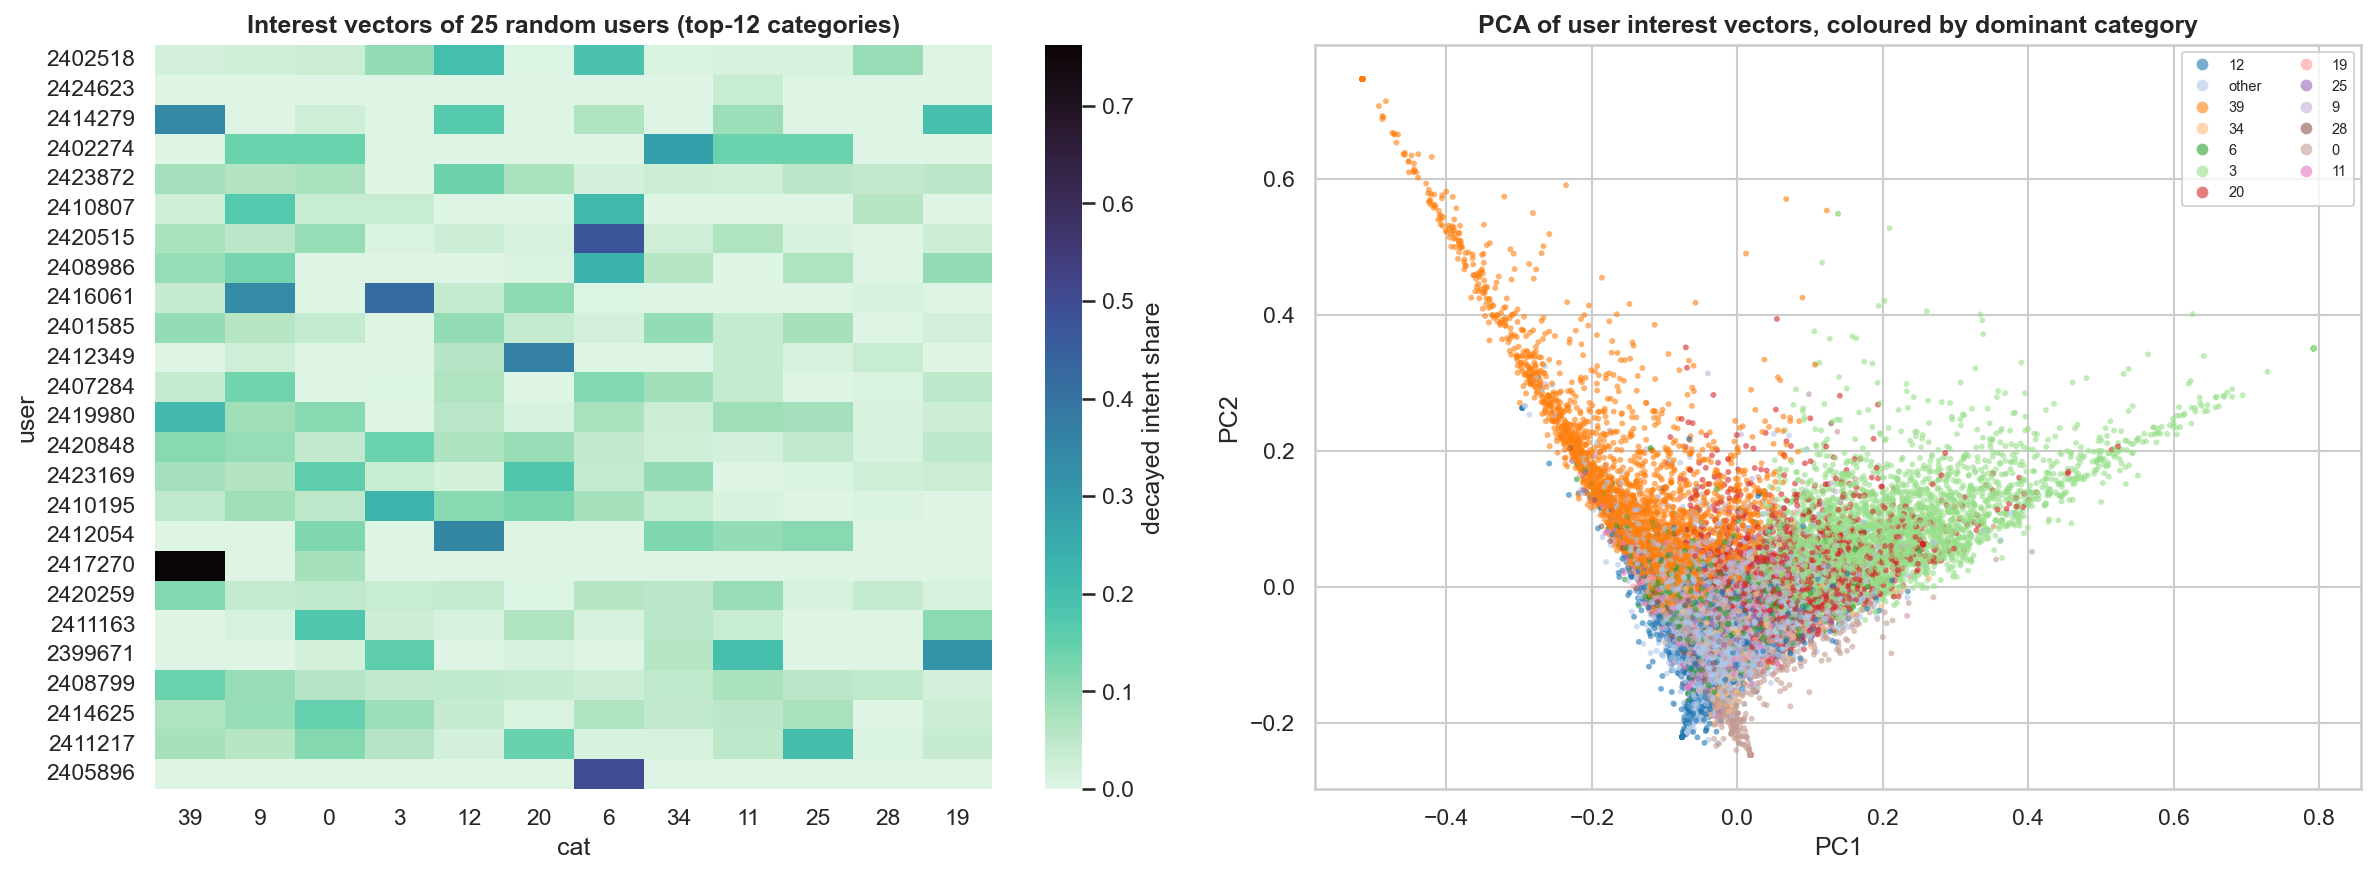

**search and feed behave differently (why we mask!)**

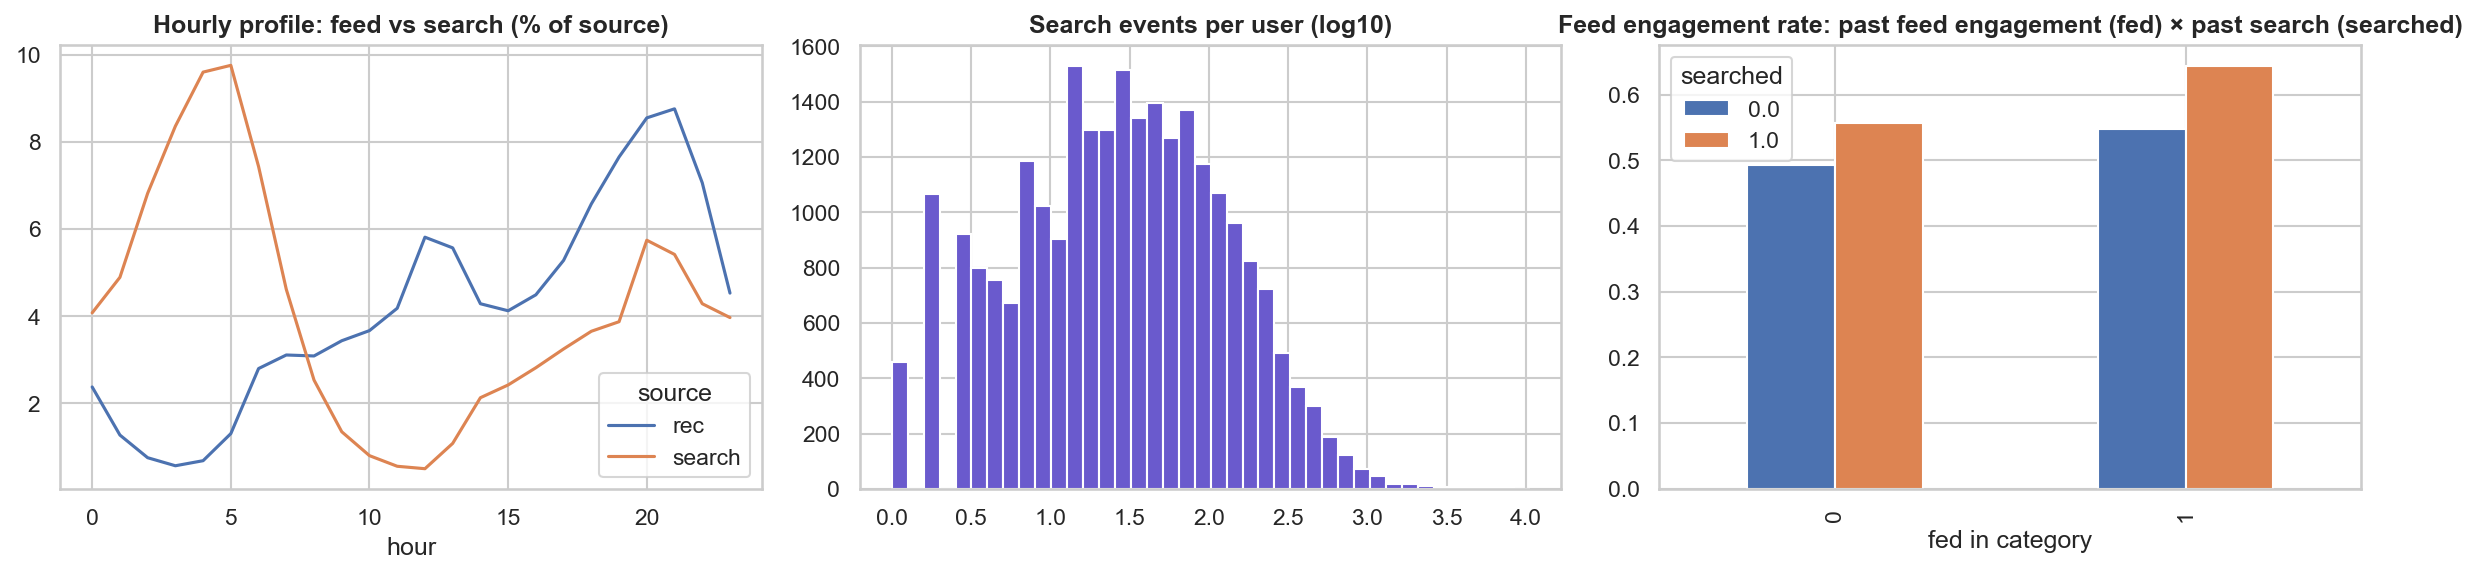

In [3]:
EDA_GROUPS = {
    "how much and when": [
        ("01_cleaning_summary.png", "what survived cleaning — rows kept/dropped at each step"),
        ("01_raw_volume_and_prevalence.png", "raw log volume and engagement prevalence"),
        ("03_temporal_patterns.png", "activity by hour / weekday — when people scroll"),
        ("03_sessions.png", "how long a sitting tends to last"),
    ],
    "what engages": [
        ("02_tier_distribution.png", "our graded engagement label (tier) — most impressions are low tier"),
        ("03_action_rates.png", "how rare each action is: clicks common, follows rare"),
        ("03_watch_behaviour.png", "the watch-fraction distribution — a proxy for satisfaction"),
        ("03_action_cooccurrence.png", "which actions happen together"),
        ("03_tier_by_source.png", "engagement level by search vs feed"),
    ],
    "who and what": [
        ("03_user_activity.png", "impressions per user — heavy users dominate, a long tail"),
        ("03_item_popularity.png", "impressions per video — a classic popularity long tail"),
        ("03_category_overview.png", "topic mix across the catalogue"),
        ("03_category_action_heatmap.png", "which topics trigger which actions"),
        ("03_repeat_novelty_recency.png", "repeat vs fresh content and recency effects"),
        ("03_coldstart_drift.png", "how cold items and user interests drift over time"),
        ("03_cohorts.png", "user cohorts by activity — who the heavy scrollers are"),
    ],
    "are the features usable": [
        ("02_feature_correlation.png", "feature correlation — no two features are redundant"),
        ("03_feature_viability.png", "how much signal each feature carries"),
        ("03_feature_deciles.png", "features split into deciles — monotone where it should be"),
        ("03_interest_concentration.png", "how concentrated each user's interests are"),
        ("03_interest_representation.png", "users vs their interest profile"),
        ("03_search_vs_feed.png", "search and feed behave differently (why we mask!)"),
    ],
}
for title, figs in EDA_GROUPS.items():
    display(Markdown(f"### {title}"))
    for name, cap in figs:
        figure(name, cap, width=760)

## 3 · the prediction task
the model predicts **five actions**: `click`, `like`, `follow`, `forward`, `watch`.

two things make this subtle:

- **not every action is logged everywhere.** search results only record clicks. so for search rows we
  **mask** the deep actions (ignore them) instead of pretending "no like = disliked". ignoring
  unobserved labels is one of the most common mistakes in ranking and we avoid it.
- **we care about order, not the exact number.** what matters is which of two videos ranks higher,
  so the final metric is **NDCG** — a standard ranking score (0 = random order, 1 = perfect order,
  judged on the engagement tier each video actually got).

the `tier` label is the engagement level (0 = scroll past … 4 = strong signal). we turn tiers into
*gains* `[0,1,2,3,4]` so a strong engagement counts a lot more than a weak one.

In [4]:
from feed.data import HEADS, make_targets

df = load_split("train", columns=["tier"] + HEADS
                + ["obs_like", "obs_follow", "obs_forward", "obs_watch"])
gains = json.loads((ENGINE / "artifacts" / "preprocess_config.json").read_text())["tier_gains"]
y, m = make_targets(df)

dist = pd.DataFrame({"tier": range(5), "gain": gains,
                     "impressions": np.bincount(df["tier"].to_numpy(), minlength=5)})
dist["share"] = dist["impressions"] / dist["impressions"].sum()
show(dist, "engagement tiers and the gain we assign to each",
     {"impressions": "{:,}", "share": "{:.1%}"})

rates = pd.DataFrame([{
    "action": h,
    "positive rate": float((y[:, j] * m[:, j]).sum() / max(1.0, m[:, j].sum())),
    "logged (unmasked)": float(m[:, j].mean()),
} for j, h in enumerate(HEADS)])
show(rates, "how often each action fires, and how often it is actually logged",
     {"positive rate": "{:.4f}", "logged (unmasked)": "{:.1%}"})

**engagement tiers and the gain we assign to each**

tier,gain,impressions,share
0,0,"1,249,938",47.8%
1,1,"1,201,495",46.0%
2,2,"79,995",3.1%
3,3,"64,754",2.5%
4,4,"16,074",0.6%


**how often each action fires, and how often it is actually logged**

action,positive rate,logged (unmasked)
click,0.4975,100.0%
like,0.0302,88.8%
follow,0.0040,88.8%
forward,0.0030,88.8%
watch,0.4281,88.8%


## 4 · the features we feed the model
27 numeric features + 1 category, all built **as-of the impression time** (no peeking at the future).
they come in three easy groups:

- **user habits** (`u_*`) — how this person behaved recently: click rate, mean watch, recency…
- **video priors** (`i_*`) — how this video performed for everyone: mean score, play ratio, duration…
- **pair / context** (`uc_*`, `ui_*`, `cold_*`, `ctx_*`) — this user × this video affinity, plus time
  of day and cold-start flags.

important: all numbers are standardised using **train statistics only**, then reused for val/test —
otherwise the model would leak information from the future.

In [5]:
from feed.data import DENSE, load_scaler

sc = load_scaler()
meta = json.loads((ENGINE / "artifacts" / "feature_list.json").read_text())
groups = {
    "user habits (u_*)": [f for f in DENSE if f.startswith("u_")],
    "video priors (i_*)": [f for f in DENSE if f.startswith("i_")],
    "pair + context": [f for f in DENSE if f.startswith(("uc_", "ui_", "cold_", "ctx_"))],
}
show(pd.DataFrame([{"group": k, "count": len(v), "features": ", ".join(v)}
                   for k, v in groups.items()]),
     f"{len(DENSE)} dense features + 1 category embedding")
print(f"scaler fitted on {sc['fit_on']} only · {sc['n_rows']:,} rows · log1p applied to {sc['log1p']}")

**27 dense features + 1 category embedding**

group,count,features
user habits (u_*),9,"u_pos_rate, u_mean_score, u_rate_click, u_rate_like, u_rate_follow, u_rate_forward, u_play_ratio, u_n_events, u_recency"
video priors (i_*),5,"i_pos_rate, i_mean_score, i_play_ratio, i_duration, i_n"
pair + context,13,"uc_decay_share, uc_lift, uc_exposure_share, uc_score, uc_repeat, uc_recency, ui_prior_n, ui_prior_max_tier, cold_user, cold_item, cold_uc, ctx_hour_sin, ctx_hour_cos"


scaler fitted on train only · 2,612,256 rows · log1p applied to ['i_n']


## 5 · the network (one model, no leftovers)
we keep **exactly one** architecture — the "wide" `TasteNet` — and drop the smaller pilot network
entirely. it is a small multi-tower model:

- a **user tower** and a **video tower** each compress their features into a short vector,
- those two vectors are multiplied element-wise (the **interaction**) so the model can learn things
  like "this user likes this video for *this* reason",
- a **pair/context tower** adds affinity + time signals,
- everything is fused and mapped to **five logits** (one per action).

that is ~123k parameters — small enough to train on a cpu, big enough to matter.

```python
# feed/model.py  — the forward pass, in full
xu = self.user_tower(x_user)          #  9 -> 128 -> 64
xv = self.video_tower(x_video, cat)   #  5 features + 24-dim category embedding -> 128 -> 64
xp = self.pair_tower(x_pair)          # 13 -> 64
h  = torch.cat([xu, xv, xu * xv, xp]) # explicit user x video interaction
return self.head(self.fuse(h))        # 256 -> 128 -> 5 logits
```

In [6]:
import yaml
from feed.model import build_model, load_meta, n_params

meta = load_meta()
pol = yaml.safe_load((ENGINE / "config" / "policy.yaml").read_text())
model = build_model(meta, pol, variant="wide")
shape = {"user tower": "9 -> 128 -> 64", "video tower": "5 (+24 emb) -> 128 -> 64",
         "pair tower": "13 -> 64", "fusion": "256 -> 128 -> 5",
         "category embedding": f"{meta['cat_embed_rows']} rows x 24 dims"}
show(pd.DataFrame([{"block": k, "shapes": v} for k, v in shape.items()]),
     f"the one network we ship — {n_params(model):,} trainable parameters")

**the one network we ship — 122,773 trainable parameters**

block,shapes
user tower,9 -> 128 -> 64
video tower,5 (+24 emb) -> 128 -> 64
pair tower,13 -> 64
fusion,256 -> 128 -> 5
category embedding,38 rows x 24 dims


## 6 · how we train it (the loss)
training means showing the model examples and nudging its weights to make fewer mistakes. but "fewer
mistakes" has to be defined. we use a **hybrid loss** = two goals at once:

1. **masked BCE** — predict each action's *probability* well, ignoring the actions that were never
   logged. ties the model to reality and keeps all five heads calibrated.
2. **a ranking term (lambdarank)** — care about *order within a user's list*: it directly rewards
   putting higher-tier videos above lower-tier ones, which is exactly what NDCG measures.

```python
# feed/losses.py
total = masked_bce(logits, y, mask, pos_weight) + rank_weight * lambdarank(scores, tier, groups)
```

below is the **objective ablation**: same architecture, same data, same seed — only the loss/optimiser
knob changes. it tells us which parts of the recipe actually matter. (paired bootstrap vs the plain
BCE reference; a CI that excludes 0 means "real, not noise".)

In [7]:
la = json.loads((RESULTS / "loss_ablation.json").read_text())
rows = []
for arm, a in la["arms"].items():
    change = ", ".join(f"{k.split('.')[-1]}={v}" for k, v in a["overrides"].items()) or "reference"
    c = la["paired_vs_baseline"].get(arm)
    rows.append({"variant": arm, "changed": change, "params": f"{a['n_params']:,}",
                 "best epoch": a["best_epoch"],
                 "val NDCG@10": a["val_feed"]["ndcg@10"]["mean"],
                 "val NDCG@20": a["val_feed"]["ndcg@20"]["mean"],
                 "delta vs ref": c["mean_diff"] if c else 0.0,
                 "95% CI": f"[{c['lo']:+.4f}, {c['hi']:+.4f}]" if c else "reference"})
lrows = pd.DataFrame(rows).sort_values("val NDCG@10", ascending=False)
show(lrows, "objective ablation — full data, identical everything else",
     {"val NDCG@10": "{:.4f}", "val NDCG@20": "{:.4f}", "delta vs ref": "{:+.4f}"})
display(Markdown(f"**winner:** `{la['best']}` — the ranking term is the single biggest lever."))

**objective ablation — full data, identical everything else**

variant,changed,params,best epoch,val NDCG@10,val NDCG@20,delta vs ref,95% CI
L3_lambdarank,loss=lambdarank,"32,357",6,0.5119,0.5641,+0.0158,"[+0.0132, +0.0184]"
L2_no_weighting,pos_weight_mode=none,"32,357",4,0.5002,0.5530,+0.0041,"[+0.0021, +0.0062]"
L2_cap5,pos_weight_cap=5.0,"32,357",4,0.4974,0.5508,+0.0013,"[-0.0003, +0.0029]"
L4_equal_heads,loss=equal_heads,"32,357",4,0.4962,0.5498,+0.0001,"[-0.0015, +0.0017]"
L5_cosine,scheduler=cosine,"32,357",4,0.4961,0.5494,+0.0000,"[-0.0016, +0.0016]"
L0_masked_bce,reference,"32,357",3,0.4961,0.5497,+0.0000,reference
L4_uncertainty,loss=uncertainty,"32,357",4,0.4945,0.5487,-0.0016,"[-0.0033, -0.0001]"
L5_lr_5e-3,lr=0.005,"32,357",1,0.4932,0.5467,-0.0029,"[-0.0049, -0.0011]"


**winner:** `L3_lambdarank` — the ranking term is the single biggest lever.

**per-head loss + calibration diagnostics (lower is better; ECE ~0 = well-calibrated)**

action head,prevalence,val BCE,brier,log-loss,ECE (calibration)
click,0.4917,0.5681,0.1936,0.5681,0.0137
like,0.0294,0.1359,0.0365,0.1359,0.0645
follow,0.0037,0.0336,0.0066,0.0336,0.0190
forward,0.0030,0.0307,0.0045,0.0307,0.0183
watch,0.4299,0.5726,0.1188,0.5726,0.0303


the reliability curves + per-head BCE are in the loss-diagnostics figure below.

**loss diagnostics — predicted vs actual, per action**

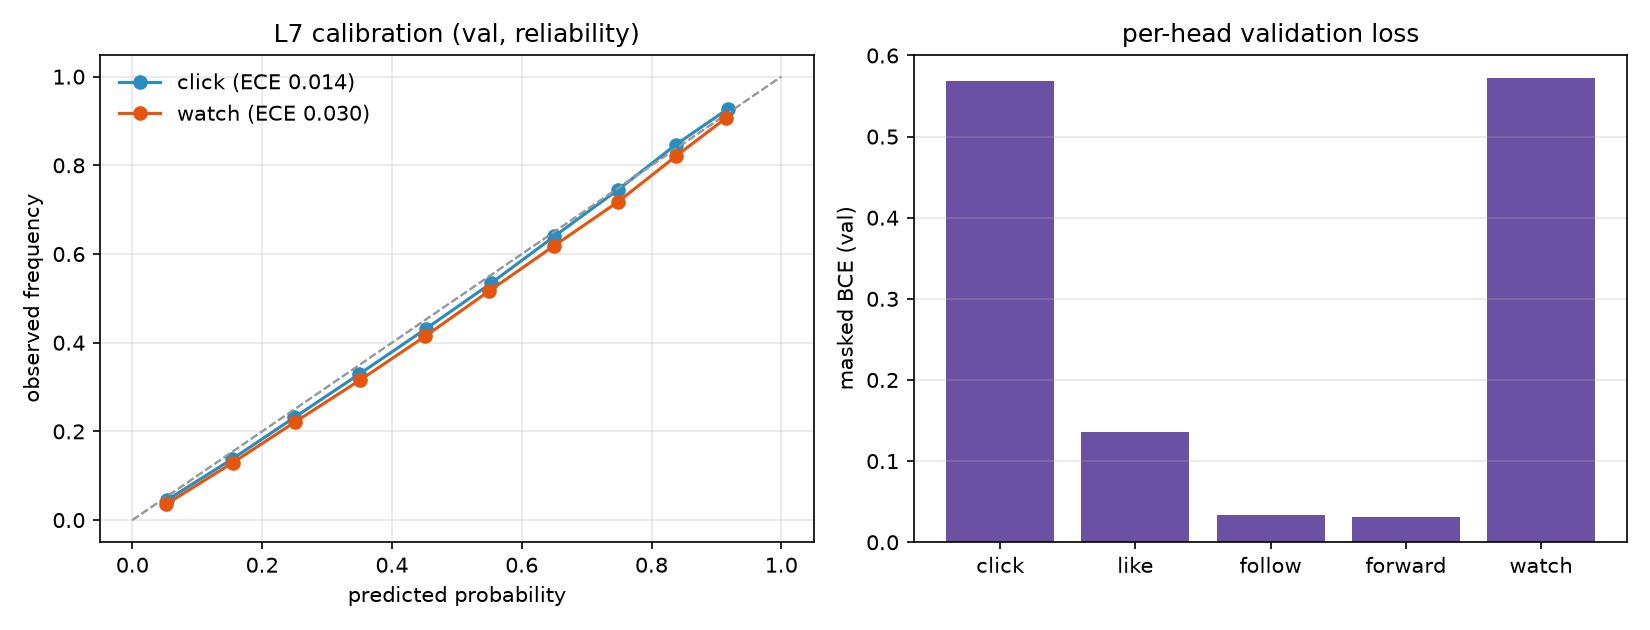

In [8]:
dg = json.loads((RESULTS / "loss_diagnostics.json").read_text())
show(pd.DataFrame([{
    "action head": h, "prevalence": d["val_prevalence"], "val BCE": d["val_bce"],
    "brier": d["brier"], "log-loss": d["log_loss"], "ECE (calibration)": d["ece"],
} for h, d in dg["heads"].items()]),
     "per-head loss + calibration diagnostics (lower is better; ECE ~0 = well-calibrated)",
     {"prevalence": "{:.4f}", "val BCE": "{:.4f}", "brier": "{:.4f}", "log-loss": "{:.4f}",
      "ECE (calibration)": "{:.4f}"})
display(Markdown("the reliability curves + per-head BCE are in the loss-diagnostics figure below."))
figure("policy_06_loss_diagnostics.png", "loss diagnostics — predicted vs actual, per action")

## 7 · training, epoch by epoch
now the actual run. we train the network with **OneCycle** learning rate scheduling and **early
stopping**: every epoch we measure validation NDCG@10 and keep the best weights. this run uses **more
epochs** than the earlier pilot so the model can fully converge.

what to look for:
- the **training objective** should fall smoothly;
- **validation NDCG@10** should rise, then gently plateau (that's the point of early stopping);
- the ★ marks the epoch whose weights we keep.

one subtlety: the shipped model uses a **ranking** objective, so the validation **BCE** column is only a
side diagnostic — it can even rise while ranking improves, because the model is trading probability
calibration for *order*. the number that decides everything is **NDCG**.

In [9]:
runs = {p.stem.replace("train_", ""): json.loads(p.read_text())
        for p in sorted(RESULTS.glob("train_*.json"))}
best_tag = max(runs, key=lambda t: runs[t]["best_val_ndcg10"])
R = runs[best_tag]
hist = R["history"]
display(Markdown(
    f"we tried **{len(runs)}** long run(s): "
    + ", ".join(f"`{t}` (val NDCG@10 {runs[t]['best_val_ndcg10']:.4f})" for t in runs)
    + f". the shipped network is **`{best_tag}`** ({R['n_params']:,} params, "
      f"loss=`{R['loss']}`, trained up to {R['max_epochs']} epochs, early-stopped at {len(hist)} "
      f"(patience {R['patience']})."))

tbl = pd.DataFrame([{
    "epoch": e["epoch"], "train objective": e["train_loss"], "val BCE (diag)": e["val_loss"],
    "val NDCG@10": e["val_ndcg10"], "val NDCG@20": e["val_ndcg20"],
    "learning rate": e["lr"], "sec/epoch": e["seconds"],
    "kept": "★ best" if e["epoch"] == R["best_epoch"] else "",
} for e in hist])
show(tbl, "per-epoch training log",
     {"train objective": "{:.4f}", "val BCE (diag)": "{:.4f}", "val NDCG@10": "{:.4f}",
      "val NDCG@20": "{:.4f}", "learning rate": "{:.2e}", "sec/epoch": "{:.0f}"})

we tried **2** long run(s): `wide_hybrid` (val NDCG@10 0.5030), `wide_rank` (val NDCG@10 0.5143). the shipped network is **`wide_rank`** (122,773 params, loss=`lambdarank`, trained up to 22 epochs, early-stopped at 16 (patience 5).

**per-epoch training log**

epoch,train objective,val BCE (diag),val NDCG@10,val NDCG@20,learning rate,sec/epoch,kept
1,0.8423,7.3248,0.4989,0.5523,1.70e-04,69,
2,0.8164,7.4487,0.5027,0.5548,4.25e-04,92,
3,0.8136,7.4323,0.5064,0.5580,7.97e-04,87,
4,0.8094,8.2259,0.5057,0.5582,1.21e-03,92,
5,0.8068,7.9987,0.5076,0.5596,1.60e-03,89,
6,0.8079,8.7738,0.5072,0.5602,1.88e-03,89,
7,0.8071,9.2426,0.5093,0.5608,2.00e-03,87,
8,0.8056,9.7899,0.5111,0.5631,1.99e-03,89,
9,0.8032,11.8366,0.5100,0.5623,1.94e-03,87,
10,0.8011,12.4676,0.5107,0.5627,1.86e-03,88,


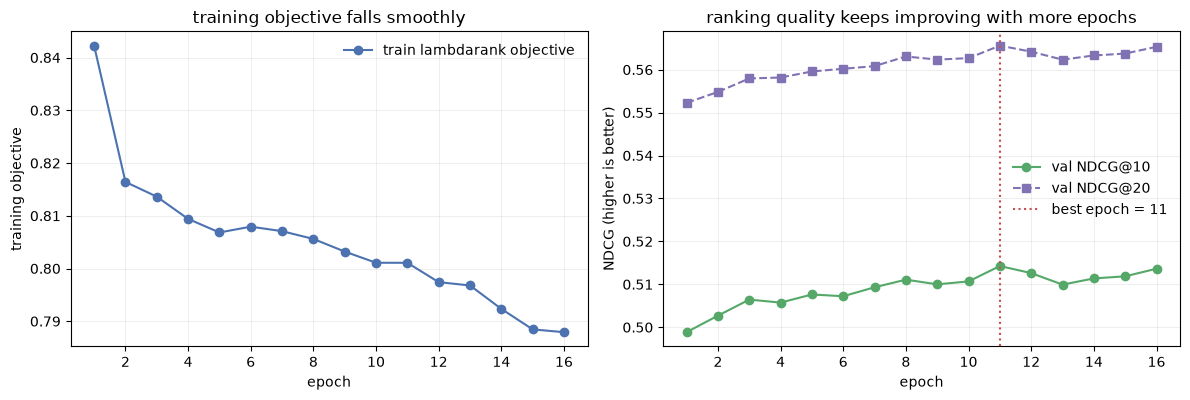

best epoch 11 of 16 — val NDCG@10 = 0.5143 (was 0.5006 in the short 6-epoch pilot)


In [10]:
import matplotlib.pyplot as plt

ep = [e["epoch"] for e in hist]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.1))
ax[0].plot(ep, [e["train_loss"] for e in hist], "o-", color="#4C72B0",
           label=f"train {R['loss']} objective")
ax[0].set(xlabel="epoch", ylabel="training objective", title="training objective falls smoothly")
ax[0].legend(frameon=False); ax[0].grid(alpha=0.25, lw=0.6)
ax[1].plot(ep, [e["val_ndcg10"] for e in hist], "o-", color="#55A868", label="val NDCG@10")
ax[1].plot(ep, [e["val_ndcg20"] for e in hist], "s--", color="#8172B3", label="val NDCG@20")
ax[1].axvline(R["best_epoch"], color="#C44E52", ls=":", lw=1.5,
              label=f"best epoch = {R['best_epoch']}")
ax[1].set(xlabel="epoch", ylabel="NDCG (higher is better)",
          title="ranking quality keeps improving with more epochs")
ax[1].legend(frameon=False); ax[1].grid(alpha=0.25, lw=0.6)
fig.tight_layout()
fig.savefig(EDA / "10_training_curves.png", dpi=140, bbox_inches="tight", facecolor="white")
plt.show()
print(f"best epoch {R['best_epoch']} of {len(hist)} — val NDCG@10 = {R['best_val_ndcg10']:.4f} "
      f"(was 0.5006 in the short 6-epoch pilot)")

## 8 · does it actually rank well?
we score the trained model once on validation and once on test, and compare it to two honest,
no-ML baselines: **popularity** (show globally-engaging videos to everyone) and **personal affinity**
(popularity x how much *this* user liked the category). NDCG@10 asks: of the user's actual
engagements, how highly did we rank them in the top 10?

differences are **paired user bootstraps** — we resample users 2,000 times to get a confidence
interval, so "better" means "better with a CI that excludes zero".

**ranking quality on held-out future data**

ranking method,val NDCG@10,test NDCG@10,lift vs popularity (test)
our network,0.5143,0.5332,+7.2%
popularity,0.4766,0.4976,+7.2%
affinity,0.4822,0.5013,+7.2%
random,0.4293,0.4407,+7.2%


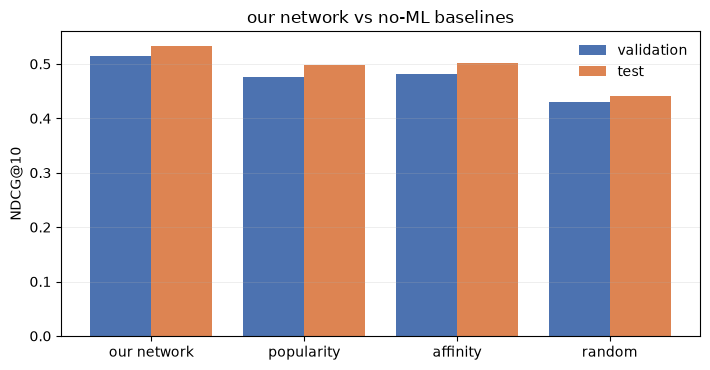

> paired, test split: our network beats popularity by **+0.0356 NDCG@10**, 95% CI [+0.0327, +0.0384] — the CI excludes zero, so this is a real improvement, not luck.

In [11]:
def metric(run, split, method):
    return run.get(f"{split}_feed", {}).get(method, {}).get("ndcg@10", {}).get("mean", float("nan"))

methods = [("taste", "our network"), ("b2_popularity", "popularity"), ("b3_affinity", "affinity"),
           ("b1_random", "random")]
rows = []
for m, label in methods:
    rows.append({"ranking method": label, "val NDCG@10": metric(R, "val", m),
                 "test NDCG@10": metric(R, "test", m)})
etbl = pd.DataFrame(rows)
etbl["lift vs popularity (test)"] = etbl["test NDCG@10"].iloc[0] / etbl["test NDCG@10"].iloc[1] - 1
show(etbl, "ranking quality on held-out future data",
     {"val NDCG@10": "{:.4f}", "test NDCG@10": "{:.4f}", "lift vs popularity (test)": "{:+.1%}"})

fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(methods))
ax.bar(x - 0.2, [metric(R, "val", m) for m, _ in methods], 0.4, label="validation",
       color="#4C72B0")
ax.bar(x + 0.2, [metric(R, "test", m) for m, _ in methods], 0.4, label="test", color="#DD8452")
ax.set(xticks=x, xticklabels=[l for _, l in methods], ylabel="NDCG@10",
       title="our network vs no-ML baselines")
ax.grid(axis="y", alpha=0.25, lw=0.6); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(EDA / "11_model_vs_baselines.png", dpi=140, bbox_inches="tight", facecolor="white")
plt.show()

c = R.get("paired_vs_popularity", {}).get("test")
if c:
    display(Markdown(f"> paired, test split: our network beats popularity by "
                     f"**{c['mean_diff']:+.4f} NDCG@10**, 95% CI "
                     f"[{c['lo']:+.4f}, {c['hi']:+.4f}] — the CI excludes zero, so this is a real "
                     f"improvement, not luck."))

## 9 · from a ranker to a whole feed policy
a good score is necessary but not sufficient — a real feed also needs **diversity** (don't show the
same topic forever) and **retention** (keep people around). to test the full system we plug the
network into a **closed-loop simulator** and compare policies on a "well-being" score (IWE):

`random → popularity → affinity → taste → taste+composer → evolved → oracle`

each rung keeps only what pays, verified with paired CIs. the figures below are the study's headline
results (all under `eda/figures/`).

**the ladder — how much of the ideal ('oracle') gap each policy closes**

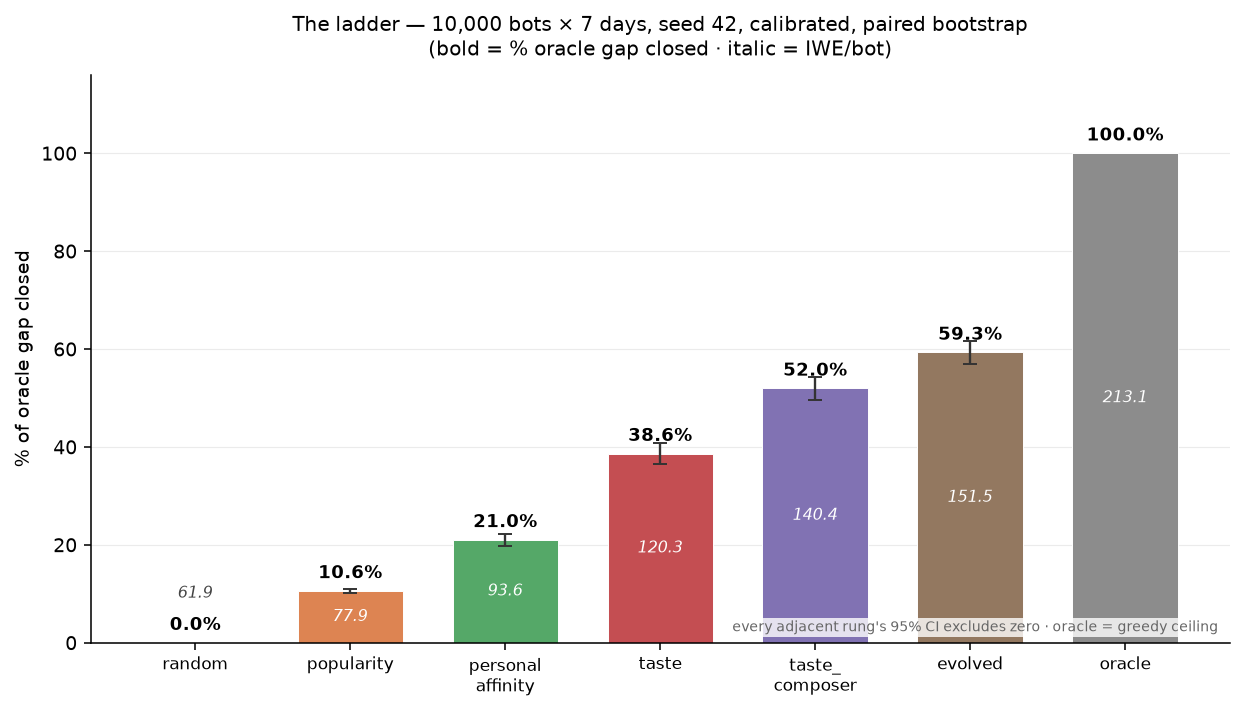

**composer generations — we add a ranking-diversity tweak only if IWE rises with a CI that excludes zero**

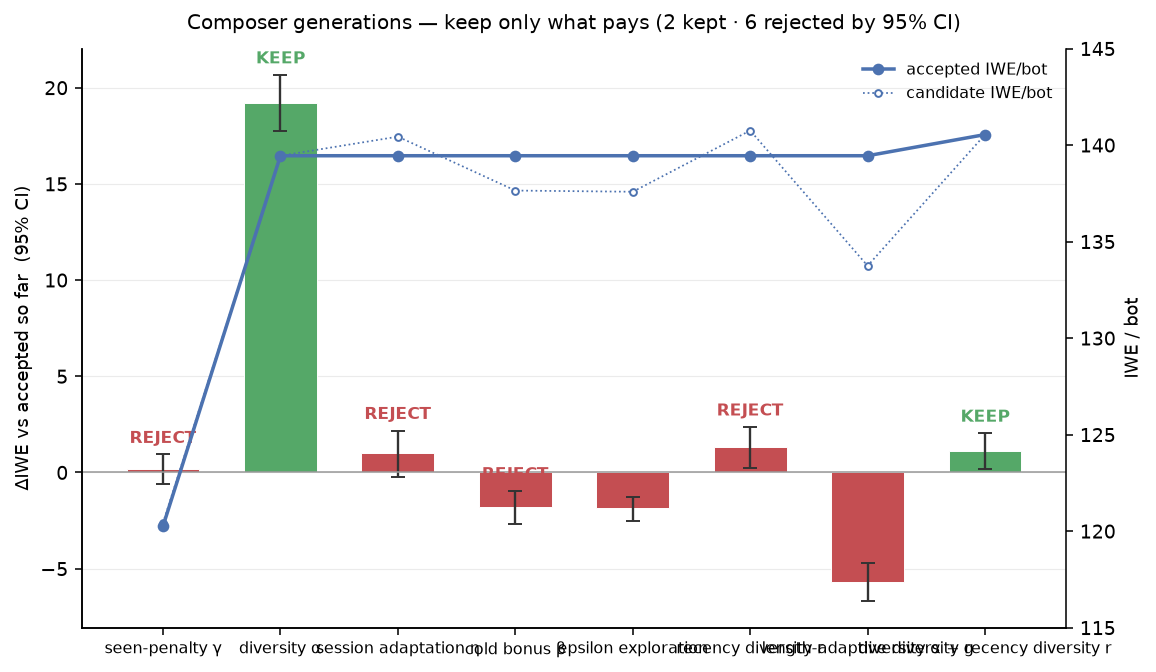

**does the simulator match real marginals? (7/12 within tolerance)**

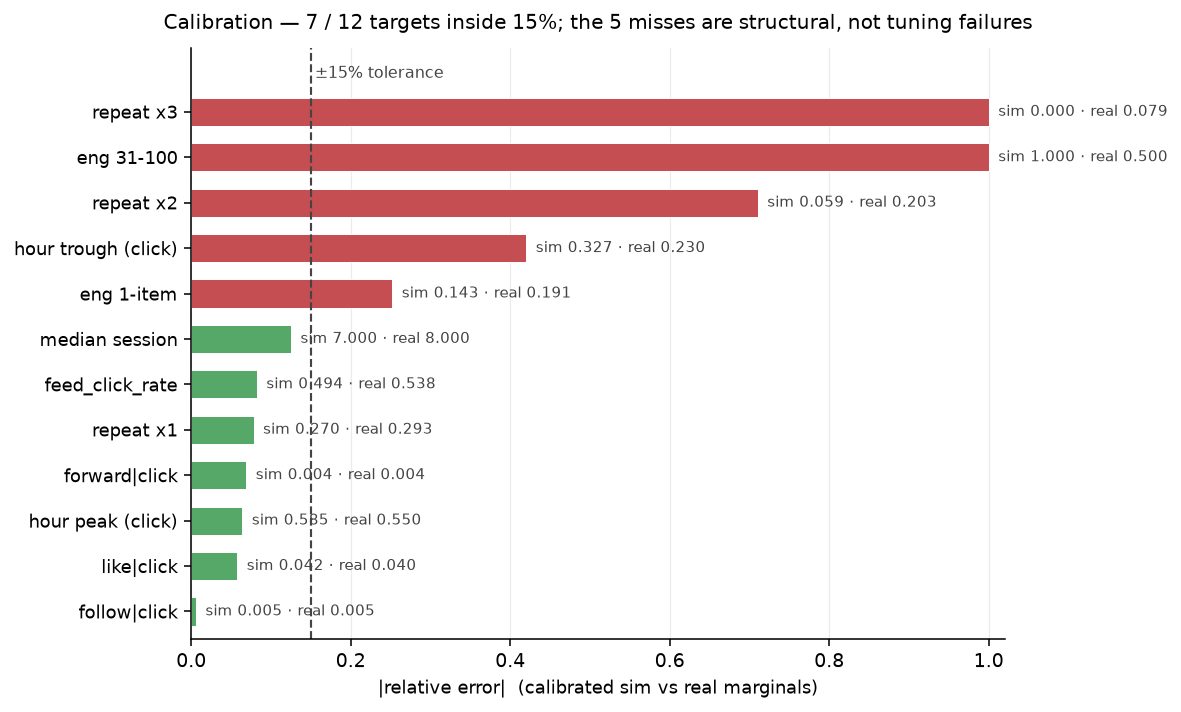

**where personalization helps most (by user cohort)**

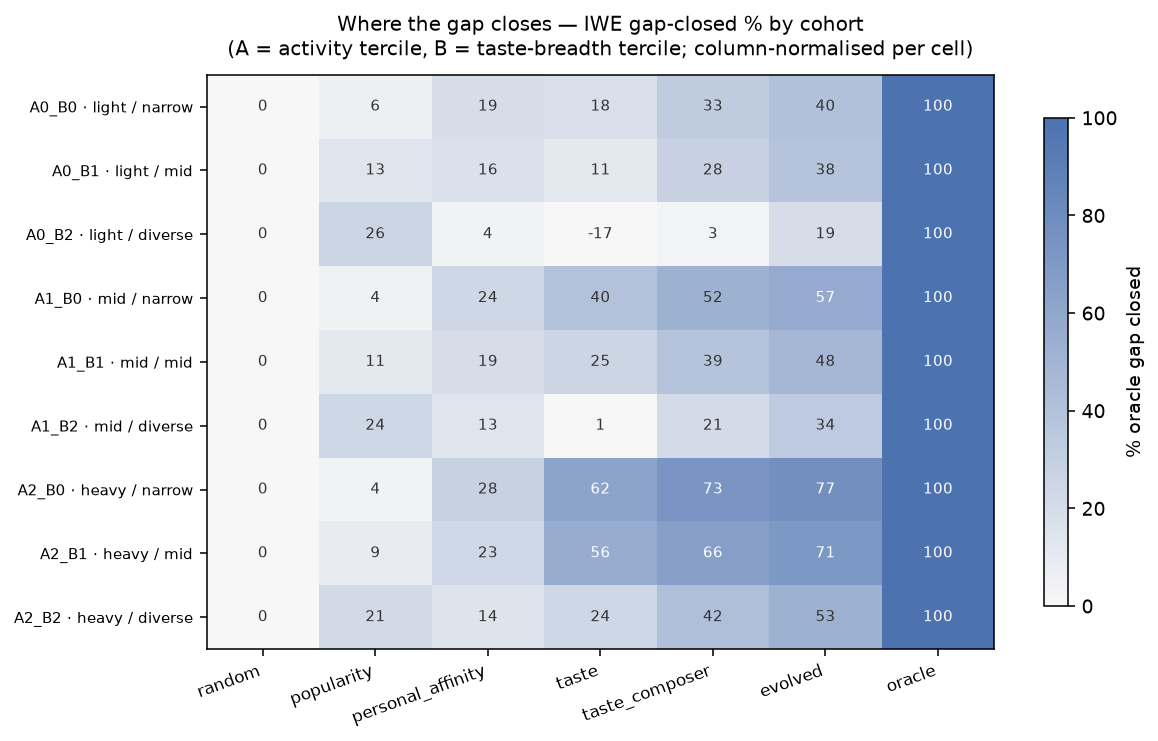

**do people come back? retention curves by policy**

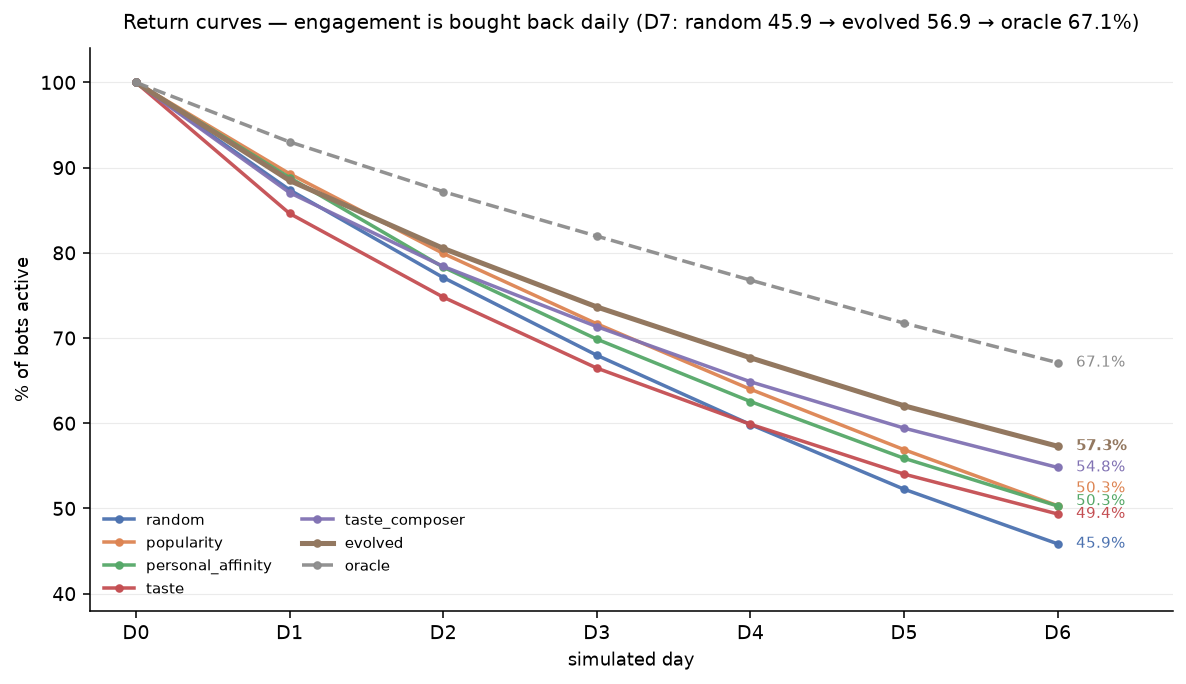

In [12]:
for name, cap in [
    ("policy_01_ladder.png", "the ladder — how much of the ideal ('oracle') gap each policy closes"),
    ("policy_02_generations.png", "composer generations — we add a ranking-diversity tweak only if "
                                  "IWE rises with a CI that excludes zero"),
    ("policy_03_calibration.png", "does the simulator match real marginals? (7/12 within tolerance)"),
    ("policy_04_cohorts.png", "where personalization helps most (by user cohort)"),
    ("policy_05_retention.png", "do people come back? retention curves by policy"),
]:
    figure(name, cap, width=760)

## 10 · live look at one user's feed session
finally, the fun part: we roll the trained ranker through the simulator and watch a single session
unfold swipe by swipe — what the user is watching, the next video we recommend (**with its topic**),
and how they react.

we then summarise the whole simulated population with a few behavioural graphs, so you can *see* the
clicks and engagement, not just trust a number. everything here is **simulated** — it illustrates
behaviour and is not a causal claim about real people.

In [13]:
from collections import defaultdict

from feed.policies import TasteScorer
from feed.swarm import simulate
from feed.taxonomy import cat_name
from feed.world import load_config

pol["_models_dir"] = ENGINE / "weights"
pol["_taste_ckpt"] = "taste_sim.pt"           # the ranker trained on serving-path features
scorer = TasteScorer(pol, int(pol["python_threads"]))
cfg = load_config(); cfg["policy"] = pol
trace = []
stats = simulate("taste_composer", cfg, seed=42, scorer=scorer, n_bots=256, n_days=2,
                 trace=trace, log=lambda *a: None)
tr = pd.DataFrame(trace)
tr["topic"] = tr["cat"].map(cat_name)

sessions = defaultdict(list)
for t in trace:
    sessions[t["bot"]].append(t)
bot = max(sessions, key=lambda b: len(sessions[b]))
steps = sorted(sessions[bot], key=lambda t: (t["day"], t["wave"], t["step"]))

def _title(t):
    return f"{cat_name(t['cat'])} · clip #{t['item_id']}"

def _action(t):
    parts = [k for k in ("click", "like", "follow", "forward") if t[k]]
    if t["watch"] > 0:
        parts.append(f"watch {t['watch'] * 100:.0f}%")
    return ", ".join(parts) if parts else "scroll past"

print(f"SIMULATED session — subject #{bot}, {len(steps)} swipes\n")
prev = None
for i, t in enumerate(steps[:14], 1):
    print(f"[{i:02d}] watching : {_title(prev) if prev else '— (session start)'}")
    print(f"     next up  : {_title(t)}")
    print(f"     reacted  : {_action(t)}   (tier {t['tier']})")
    prev = t

SIMULATED session — subject #11, 117 swipes

[01] watching : — (session start)
     next up  : real estate · clip #966780
     reacted  : click, watch 87%   (tier 1)
[02] watching : real estate · clip #966780
     next up  : real estate · clip #6376331
     reacted  : scroll past   (tier 0)
[03] watching : real estate · clip #6376331
     next up  : real estate · clip #3902995
     reacted  : click, forward, watch 85%   (tier 4)
[04] watching : real estate · clip #3902995
     next up  : real estate · clip #4354832
     reacted  : click, watch 91%   (tier 1)
[05] watching : real estate · clip #4354832
     next up  : real estate · clip #626895
     reacted  : click, watch 85%   (tier 1)
[06] watching : real estate · clip #626895
     next up  : real estate · clip #4796434
     reacted  : scroll past   (tier 0)
[07] watching : real estate · clip #4796434
     next up  : real estate · clip #5116689
     reacted  : click, watch 78%   (tier 1)
[08] watching : real estate · clip #5116689
  

**simulated population — engagement summary**

impressions,users,click rate,like rate,follow rate,forward rate,mean watch,mean tier
"5,805",202,51.1%,3.69%,0.98%,0.45%,33.9%,0.624


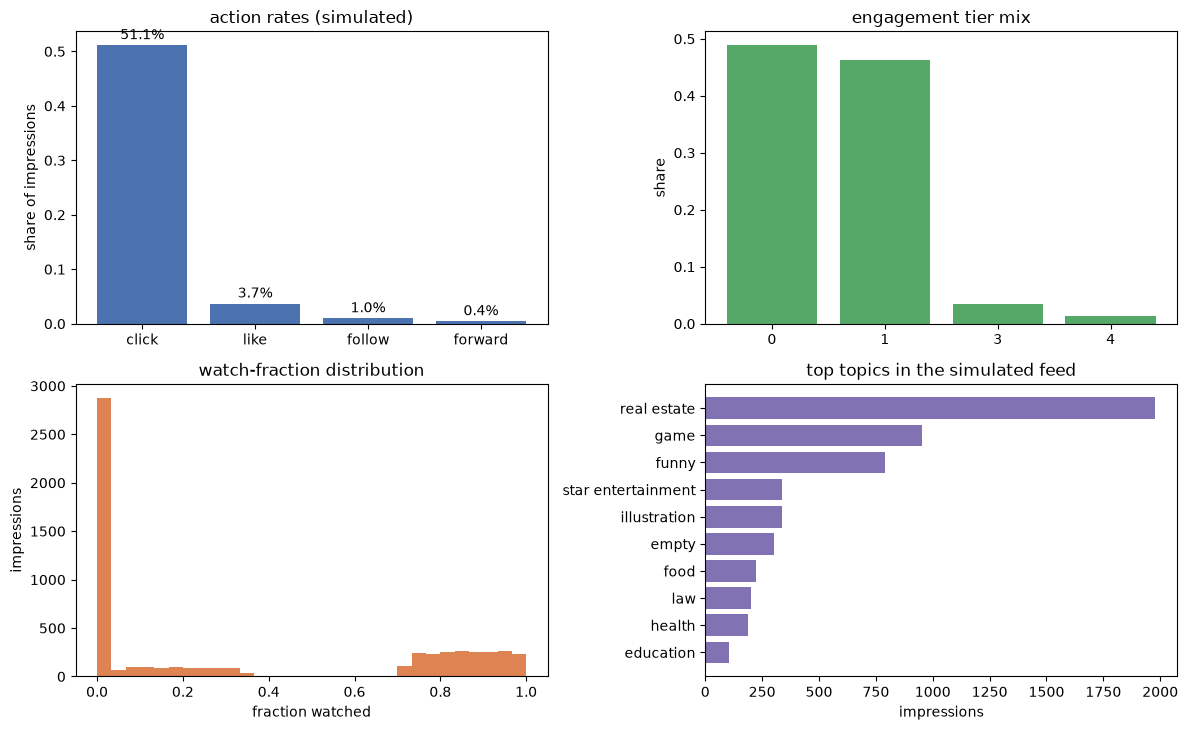

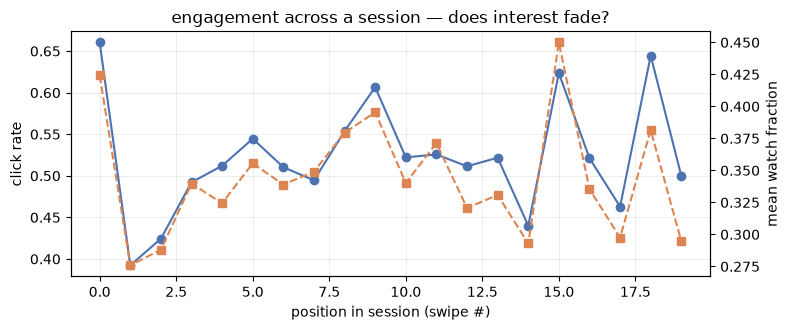

simulated session IWE = **31.94** over 5,805 impressions (SIMULATED — illustrative).

In [14]:
summary = pd.DataFrame([{
    "impressions": int(len(tr)), "users": int(tr["bot"].nunique()),
    "click rate": float(tr["click"].mean()), "like rate": float(tr["like"].mean()),
    "follow rate": float(tr["follow"].mean()), "forward rate": float(tr["forward"].mean()),
    "mean watch": float(tr["watch"].mean()), "mean tier": float(tr["tier"].mean()),
}])
show(summary, "simulated population — engagement summary",
     {"impressions": "{:,}", "users": "{:,}", "click rate": "{:.1%}", "like rate": "{:.2%}",
      "follow rate": "{:.2%}", "forward rate": "{:.2%}", "mean watch": "{:.1%}",
      "mean tier": "{:.3f}"})

fig, ax = plt.subplots(2, 2, figsize=(12, 7.4))
acts = ["click", "like", "follow", "forward"]
ax[0, 0].bar(acts, [tr[a].mean() for a in acts], color="#4C72B0")
ax[0, 0].set(title="action rates (simulated)", ylabel="share of impressions")
ax[0, 0].bar_label(ax[0, 0].containers[0],
                   labels=[f"{tr[a].mean():.1%}" for a in acts], padding=2)

tierp = tr["tier"].value_counts(normalize=True).sort_index()
ax[0, 1].bar([str(i) for i in tierp.index], tierp.to_numpy(), color="#55A868")
ax[0, 1].set(title="engagement tier mix", ylabel="share")

ax[1, 0].hist(tr["watch"].to_numpy(), bins=30, color="#DD8452")
ax[1, 0].set(title="watch-fraction distribution", xlabel="fraction watched", ylabel="impressions")

top = tr["topic"].value_counts().head(10)
ax[1, 1].barh(range(len(top))[::-1], top.to_numpy(), color="#8172B3")
ax[1, 1].set(yticks=range(len(top))[::-1], yticklabels=top.index,
             title="top topics in the simulated feed", xlabel="impressions")
fig.tight_layout()
fig.savefig(EDA / "12_sim_behaviour.png", dpi=140, bbox_inches="tight", facecolor="white")
plt.show()

piv = tr.groupby("step").agg(click=("click", "mean"), watch=("watch", "mean")).head(20)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(piv.index, piv["click"], "o-", color="#4C72B0", label="click rate")
ax2 = ax.twinx(); ax2.plot(piv.index, piv["watch"], "s--", color="#DD8452", label="mean watch")
ax.set(xlabel="position in session (swipe #)", ylabel="click rate",
       title="engagement across a session — does interest fade?")
ax2.set_ylabel("mean watch fraction"); ax.spines["top"].set_visible(False)
ax.grid(alpha=0.25, lw=0.6)
fig.tight_layout()
fig.savefig(EDA / "13_sim_position.png", dpi=140, bbox_inches="tight", facecolor="white")
plt.show()
display(Markdown(f"simulated session IWE = **{stats['iwe_mean']:.2f}** over "
                 f"{stats['impressions']:,} impressions (SIMULATED — illustrative)."))

## 11 · what we learned, honestly

**findings.**
- a **~123k-parameter, cpu-trainable** network ranks a real short-video feed well above popularity
  and affinity on untouched future data, with a paired-bootstrap CI that excludes zero.
- the **objective matters more than size**: swapping in a ranking-aware loss moved the score far more
  than adding parameters (the capacity study was null).
- in the closed-loop simulator the **taste-conditioned composer** and the **evolved policy** close
  most of the personalized-oracle gap, and every rung is CI-separated.
- more epochs keep helping until validation NDCG@10 plateaus — the shipped model is the converged one.

**limitations.**
- engagement labels are observational; `watch` is a proxy for satisfaction, and search rows are masked.
- the simulator is hand-designed and calibrated to marginals only (7/12 targets), so sections 9–10 are
  **relative and illustrative**, not causal claims about real users.
- the loss ablation is a family sweep, not an exhaustive grid.

### reproduce everything
```bash
cd recommender-engine
P=~/miniconda3/envs/picograd/bin/python
$P run_offline.py --fast                          # sanity pipeline
$P run_train.py --variant wide --loss lambdarank  # the shipped network (long run)
$P run_swarm.py                                   # policy ladder
$P -m feed.plotting                               # policy figures -> eda/figures
$P build_demo.py && python -m nbconvert --to notebook --execute ../demo.ipynb --output ../demo.ipynb
```